In [ ]:
# ============================================================
# Block 1: Imports and config
# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Optional: only needed in Colab
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# -------- USER SETTINGS --------
FOLDER_PATH = "/content/drive/My Drive/Subj1--Tomorrow_full"
#FOLDER_PATH = "https://drive.google.com/drive/folders/1sD9SeTFQriZEIvlm_Ccp2ah1_EDJaew0?usp=drive_link"
REPRESENTATIVE_INDEX = 0   # choose which clip to analyze after listing
FRAME_STRIDE = 1           # keep as 1 for now
MAX_FRAMES = None          # set to an integer if you want to cap frames, else None
GRAYSCALE = True
RESIZE_TO = None           # e.g. (256, 192) if needed later, else None

# Display settings
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"

In [ ]:
# ============================================================
# Block 2: Mount Google Drive
# ============================================================
if IN_COLAB:
    if not os.path.exists("/content/drive"):
        drive.mount("/content/drive")
    else:
        print("Drive path already exists.")
else:
    print("Not running in Colab.")

Mounted at /content/drive


In [ ]:
# ============================================================
# Block 3: Find video files
# ============================================================
def list_video_files(folder_path, exts=(".mp4", ".avi", ".mov", ".mkv")):
    folder = Path(folder_path)
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder_path}")
    if not folder.is_dir():
        raise ValueError(f"Not a folder: {folder_path}")

    files = []
    for f in sorted(folder.iterdir()):
        if f.is_file() and f.suffix.lower() in exts and not f.name.startswith("."):
            files.append(str(f))

    return files

video_files = list_video_files(FOLDER_PATH)

print(f"Found {len(video_files)} video files:")
for i, f in enumerate(video_files):
    print(f"[{i}] {os.path.basename(f)}")

Found 20 video files:
[0] Copy of WIN_20260204_17_29_37_Pro_crop.mp4
[1] Copy of WIN_20260204_17_29_43_Pro_crop.mp4
[2] Copy of WIN_20260204_17_29_50_Pro_crop.mp4
[3] Copy of WIN_20260204_17_29_57_Pro_crop.mp4
[4] Copy of WIN_20260204_17_30_03_Pro_crop.mp4
[5] Copy of WIN_20260204_17_30_09_Pro_crop.mp4
[6] Copy of WIN_20260204_17_30_18_Pro_crop.mp4
[7] Copy of WIN_20260204_17_30_27_Pro_crop.mp4
[8] Copy of WIN_20260204_17_30_35_Pro_crop.mp4
[9] Copy of WIN_20260204_17_30_41_Pro_crop.mp4
[10] Copy of WIN_20260204_17_30_48_Pro_crop.mp4
[11] Copy of WIN_20260204_17_30_57_Pro_crop.mp4
[12] Copy of WIN_20260204_17_31_05_Pro_crop.mp4
[13] Copy of WIN_20260204_17_31_13_Pro_crop.mp4
[14] Copy of WIN_20260204_17_31_20_Pro_crop.mp4
[15] Copy of WIN_20260204_17_31_25_Pro_crop.mp4
[16] Copy of WIN_20260204_17_31_31_Pro_crop.mp4
[17] Copy of WIN_20260204_17_31_37_Pro_crop.mp4
[18] Copy of WIN_20260204_17_31_43_Pro_crop.mp4
[19] Copy of WIN_20260204_17_31_52_Pro_crop.mp4


In [ ]:
# ============================================================
# Block 4: Pick one representative clip
# ============================================================
if len(video_files) == 0:
    raise ValueError("No video files found in the folder.")

video_path = video_files[REPRESENTATIVE_INDEX]
print("Selected clip:")
print(video_path)

Selected clip:
/content/drive/My Drive/Subj1--Tomorrow_full/Copy of WIN_20260204_17_29_37_Pro_crop.mp4


In [ ]:
# ============================================================
# Block 5: Load video frames
# ============================================================
def load_video_frames(video_path, grayscale=True, resize_to=None, frame_stride=1, max_frames=None):
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    frames = []
    frame_count = 0
    kept_count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_count % frame_stride == 0:
            if grayscale:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            if resize_to is not None:
                frame = cv2.resize(frame, resize_to)

            frame = frame.astype(np.float32) / 255.0
            frames.append(frame)
            kept_count += 1

            if max_frames is not None and kept_count >= max_frames:
                break

        frame_count += 1

    cap.release()

    if len(frames) == 0:
        raise ValueError("No frames were loaded.")

    frames = np.stack(frames, axis=0)   # shape: (T, H, W)
    return frames

frames = load_video_frames(
    video_path,
    grayscale=GRAYSCALE,
    resize_to=RESIZE_TO,
    frame_stride=FRAME_STRIDE,
    max_frames=MAX_FRAMES
)

print("Loaded frames shape:", frames.shape)
print("dtype:", frames.dtype)
print("min/max:", frames.min(), frames.max())

Loaded frames shape: (49, 192, 256)
dtype: float32
min/max: 0.0 0.78039217


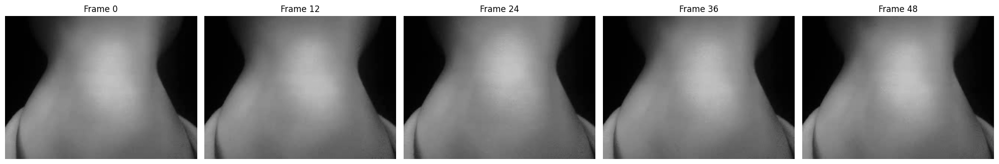

In [ ]:
# ============================================================
# Block 6: Show a few frames
# ============================================================
def show_sample_frames(frames, n=5):
    T = frames.shape[0]
    idxs = np.linspace(0, T - 1, n, dtype=int)

    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axes = [axes]

    for ax, idx in zip(axes, idxs):
        ax.imshow(frames[idx], vmin=0, vmax=1)
        ax.set_title(f"Frame {idx}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_sample_frames(frames, n=5)

In [ ]:
# ============================================================
# Block 7: Basic pilot maps
# ============================================================
mean_frame = np.mean(frames, axis=0)
var_map = np.var(frames, axis=0, ddof=1)

diff_frames = np.diff(frames, axis=0)          # shape: (T-1, H, W)
td_energy_map = np.mean(diff_frames**2, axis=0)

print("mean_frame shape:", mean_frame.shape)
print("var_map shape:", var_map.shape)
print("td_energy_map shape:", td_energy_map.shape)

mean_frame shape: (192, 256)
var_map shape: (192, 256)
td_energy_map shape: (192, 256)


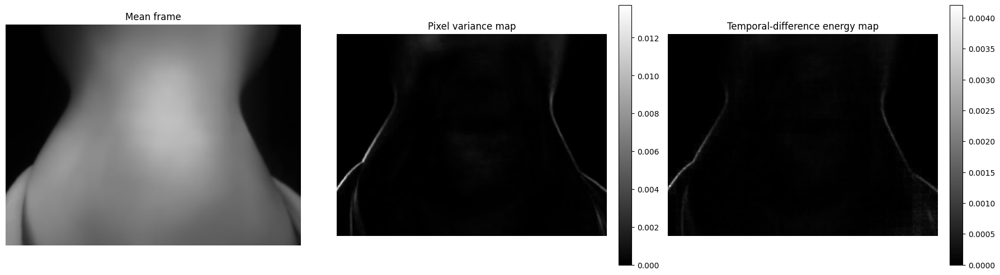

In [ ]:
# ============================================================
# Block 8: Plot mean / variance / temporal-difference energy
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(mean_frame, vmin=0, vmax=1)
axes[0].set_title("Mean frame")
axes[0].axis("off")

im1 = axes[1].imshow(var_map)
axes[1].set_title("Pixel variance map")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(td_energy_map)
axes[2].set_title("Temporal-difference energy map")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Crop box (x0, x1, y0, y1): (56, 200, 15, 177)
Cropped shape: (162, 144)


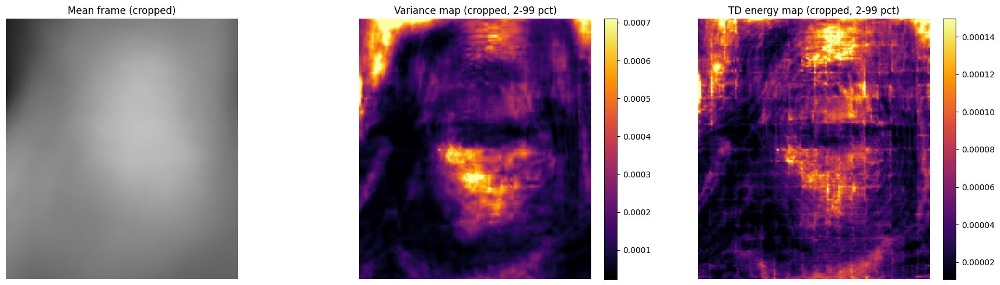

In [ ]:
# ============================================================
# Block 8 Revised: Crop + robust rescale for variance / energy maps
# ============================================================

# ---- user-tunable crop ratios ----
# fractions of full image width/height
XMIN_FRAC = 0.22
XMAX_FRAC = 0.78
YMIN_FRAC = 0.08
YMAX_FRAC = 0.92

# ---- robust display scaling ----
LOW_PCT = 2
HIGH_PCT = 99

def crop_by_fraction(img, xmin_frac, xmax_frac, ymin_frac, ymax_frac):
    H, W = img.shape
    x0 = int(np.floor(W * xmin_frac))
    x1 = int(np.ceil (W * xmax_frac))
    y0 = int(np.floor(H * ymin_frac))
    y1 = int(np.ceil (H * ymax_frac))
    return img[y0:y1, x0:x1], (x0, x1, y0, y1)

def robust_limits(img, low_pct=2, high_pct=99):
    vmin = np.percentile(img, low_pct)
    vmax = np.percentile(img, high_pct)
    if vmax <= vmin:
        vmax = img.max()
        vmin = img.min()
    return vmin, vmax

# crop all three maps in the same way
mean_crop, crop_box = crop_by_fraction(mean_frame, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
var_crop, _ = crop_by_fraction(var_map, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
td_crop, _ = crop_by_fraction(td_energy_map, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

print("Crop box (x0, x1, y0, y1):", crop_box)
print("Cropped shape:", mean_crop.shape)

# robust plotting limits for the two heatmaps
var_vmin, var_vmax = robust_limits(var_crop, LOW_PCT, HIGH_PCT)
td_vmin, td_vmax = robust_limits(td_crop, LOW_PCT, HIGH_PCT)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(mean_crop, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Mean frame (cropped)")
axes[0].axis("off")

im1 = axes[1].imshow(var_crop, cmap="inferno", vmin=var_vmin, vmax=var_vmax)
axes[1].set_title(f"Variance map (cropped, {LOW_PCT}-{HIGH_PCT} pct)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(td_crop, cmap="inferno", vmin=td_vmin, vmax=td_vmax)
axes[2].set_title(f"TD energy map (cropped, {LOW_PCT}-{HIGH_PCT} pct)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

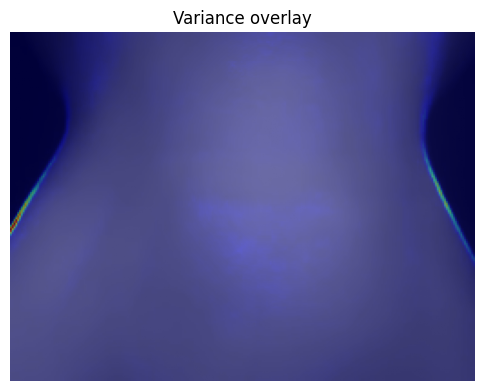

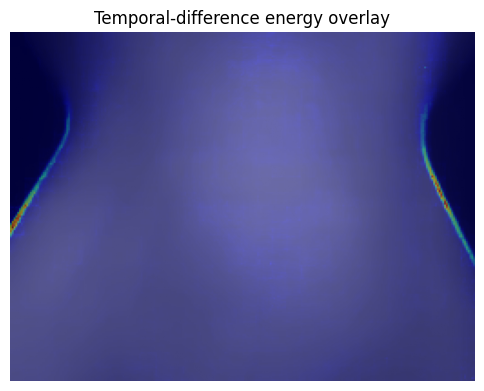

In [ ]:
# ============================================================
# Block 9: Overlay heatmaps on mean frame
# ============================================================
def overlay_heatmap(background, heatmap, alpha=0.45, cmap="jet", title="Overlay"):
    plt.figure(figsize=(6, 6))
    plt.imshow(background, cmap="gray", vmin=0, vmax=1)
    plt.imshow(heatmap, cmap=cmap, alpha=alpha)
    plt.title(title)
    plt.axis("off")
    plt.show()

overlay_heatmap(mean_frame, var_map, alpha=0.45, cmap="jet", title="Variance overlay")
overlay_heatmap(mean_frame, td_energy_map, alpha=0.45, cmap="jet", title="Temporal-difference energy overlay")

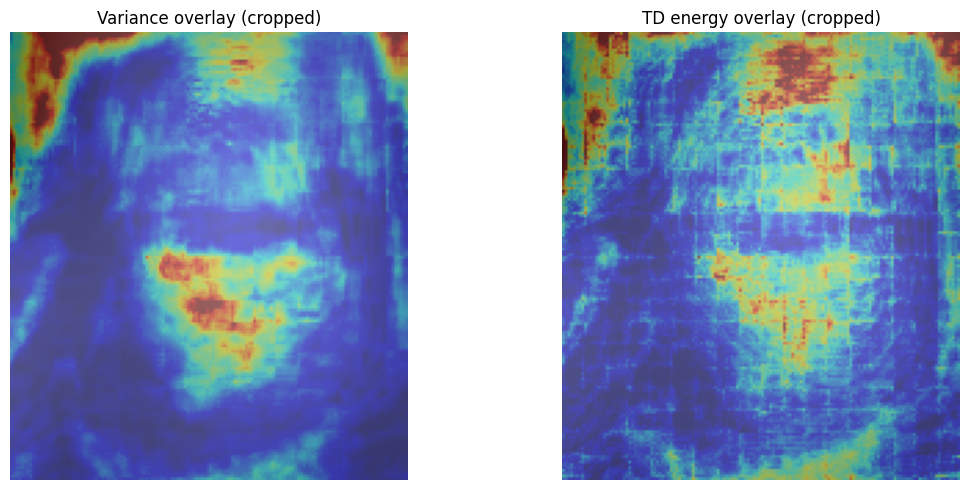

In [ ]:
# ============================================================
# Overlay revised version for the cropped maps
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(mean_crop, cmap="gray", vmin=0, vmax=1)
axes[0].imshow(var_crop, cmap="jet", alpha=0.45, vmin=var_vmin, vmax=var_vmax)
axes[0].set_title("Variance overlay (cropped)")
axes[0].axis("off")

axes[1].imshow(mean_crop, cmap="gray", vmin=0, vmax=1)
axes[1].imshow(td_crop, cmap="jet", alpha=0.45, vmin=td_vmin, vmax=td_vmax)
axes[1].set_title("TD energy overlay (cropped)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Block 10: Prepare data matrix for SVD
# ============================================================
T, H, W = frames.shape
P = H * W

X = frames.reshape(T, P).T   # shape: (P, T)

mean_vector = np.mean(X, axis=1, keepdims=True)
X_centered = X - mean_vector

print("X shape:", X.shape)
print("X_centered shape:", X_centered.shape)

X shape: (49152, 49)
X_centered shape: (49152, 49)


In [ ]:
# ============================================================
# Block 11: Run SVD
# ============================================================
U, S, VT = np.linalg.svd(X_centered, full_matrices=False)

print("U shape:", U.shape)
print("S shape:", S.shape)
print("VT shape:", VT.shape)

U shape: (49152, 49)
S shape: (49,)
VT shape: (49, 49)


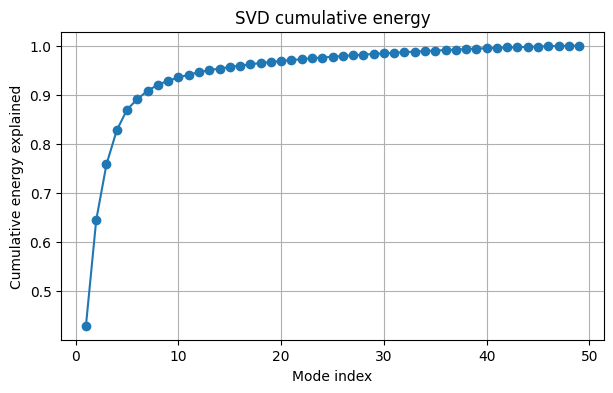

Mode 1: singular value = 15.0071, energy ratio = 0.4300
Mode 2: singular value = 10.6132, energy ratio = 0.2151
Mode 3: singular value = 7.7095, energy ratio = 0.1135
Mode 4: singular value = 6.0274, energy ratio = 0.0694
Mode 5: singular value = 4.6891, energy ratio = 0.0420
Mode 6: singular value = 3.3533, energy ratio = 0.0215
Mode 7: singular value = 2.9745, energy ratio = 0.0169
Mode 8: singular value = 2.5242, energy ratio = 0.0122
Mode 9: singular value = 2.0921, energy ratio = 0.0084
Mode 10: singular value = 1.8535, energy ratio = 0.0066


In [ ]:
# ============================================================
# Block 12: Singular values and explained energy
# ============================================================
energy = S**2
energy_ratio = energy / np.sum(energy)
cum_energy = np.cumsum(energy_ratio)

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(S)+1), cum_energy, marker="o")
plt.xlabel("Mode index")
plt.ylabel("Cumulative energy explained")
plt.title("SVD cumulative energy")
plt.grid(True)
plt.show()

for k in range(min(10, len(S))):
    print(f"Mode {k+1}: singular value = {S[k]:.4f}, energy ratio = {energy_ratio[k]:.4f}")

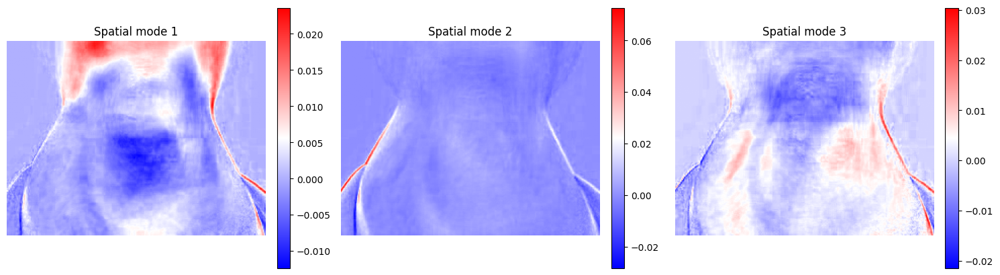

In [ ]:
# ============================================================
# Block 13: Plot first spatial modes
# ============================================================
def show_spatial_modes(U, H, W, num_modes=3):
    fig, axes = plt.subplots(1, num_modes, figsize=(5*num_modes, 5))
    if num_modes == 1:
        axes = [axes]

    for k in range(num_modes):
        mode_img = U[:, k].reshape(H, W)
        im = axes[k].imshow(mode_img, cmap="bwr")
        axes[k].set_title(f"Spatial mode {k+1}")
        axes[k].axis("off")
        plt.colorbar(im, ax=axes[k], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

show_spatial_modes(U, H, W, num_modes=3)

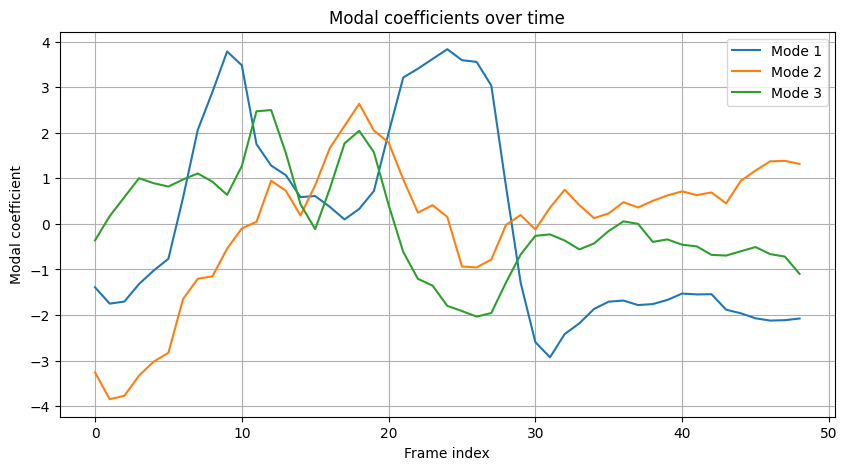

In [ ]:
# ============================================================
# Block 14: Plot modal coefficients vs frame index
# ============================================================
# Coefficients are rows of Sigma * VT
coeffs = np.diag(S) @ VT   # shape: (r, T)

num_modes_to_plot = 3
frame_axis = np.arange(T)

plt.figure(figsize=(10, 5))
for k in range(num_modes_to_plot):
    plt.plot(frame_axis, coeffs[k], label=f"Mode {k+1}")

plt.xlabel("Frame index")
plt.ylabel("Modal coefficient")
plt.title("Modal coefficients over time")
plt.legend()
plt.grid(True)
plt.show()

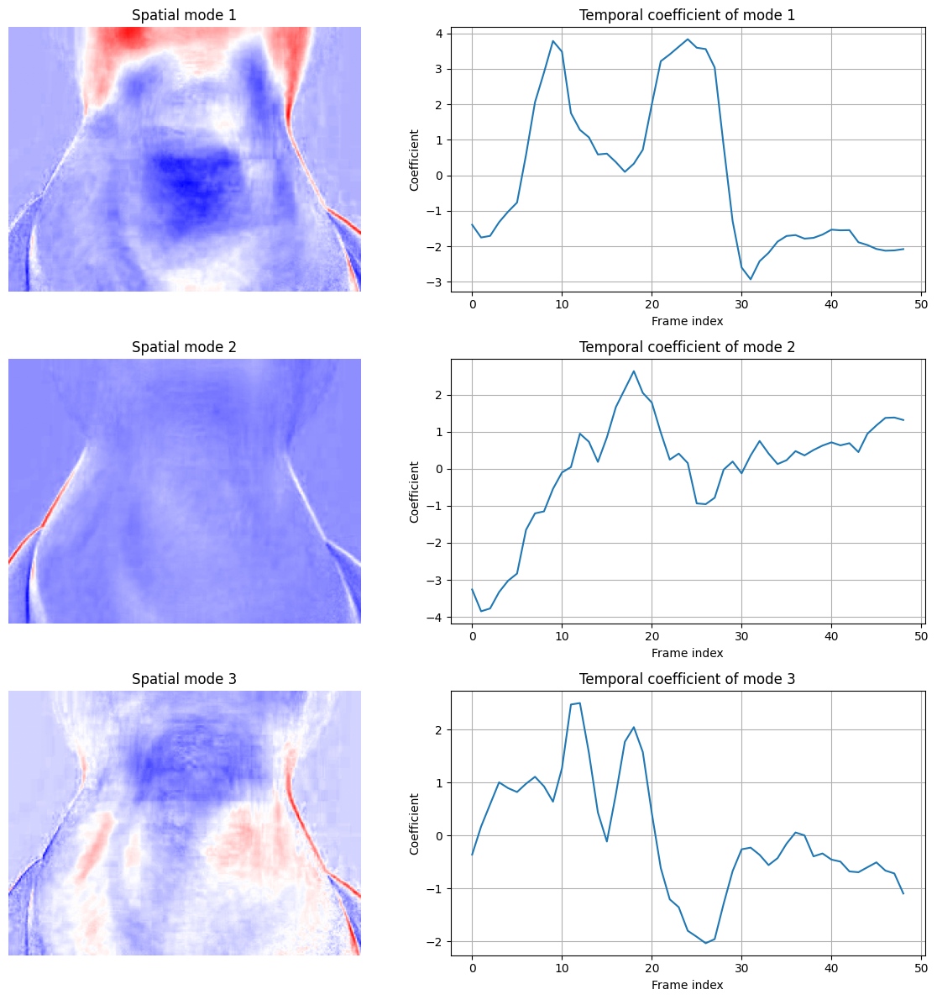

In [ ]:
# ============================================================
# Block 15: Spatial mode + temporal trace together
# ============================================================
num_modes_to_show = 3

fig, axes = plt.subplots(num_modes_to_show, 2, figsize=(12, 4*num_modes_to_show))

for k in range(num_modes_to_show):
    mode_img = U[:, k].reshape(H, W)
    axes[k, 0].imshow(mode_img, cmap="bwr")
    axes[k, 0].set_title(f"Spatial mode {k+1}")
    axes[k, 0].axis("off")

    axes[k, 1].plot(frame_axis, coeffs[k])
    axes[k, 1].set_title(f"Temporal coefficient of mode {k+1}")
    axes[k, 1].set_xlabel("Frame index")
    axes[k, 1].set_ylabel("Coefficient")
    axes[k, 1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Block 16: Load all clips and compute per-clip maps
# ============================================================

# Fallback crop defaults if not already defined
try:
    XMIN_FRAC
except NameError:
    XMIN_FRAC, XMAX_FRAC = 0.18, 0.82
    YMIN_FRAC, YMAX_FRAC = 0.08, 0.92

clips_data = []
failed_files = []

for i, vp in enumerate(video_files):
    try:
        frames_i = load_video_frames(
            vp,
            grayscale=GRAYSCALE,
            resize_to=RESIZE_TO,
            frame_stride=FRAME_STRIDE,
            max_frames=MAX_FRAMES
        )

        T_i, H_i, W_i = frames_i.shape

        if T_i < 2:
            print(f"Skipping {os.path.basename(vp)} because it has < 2 frames after loading.")
            continue

        mean_i = np.mean(frames_i, axis=0)
        var_i = np.var(frames_i, axis=0, ddof=1)
        diff_i = np.diff(frames_i, axis=0)
        td_i = np.mean(diff_i**2, axis=0)

        clips_data.append({
            "path": vp,
            "name": os.path.basename(vp),
            "frames": frames_i,
            "T": T_i,
            "H": H_i,
            "W": W_i,
            "mean": mean_i,
            "var": var_i,
            "td": td_i
        })

        print(f"[{i}] loaded {os.path.basename(vp)} | shape = {frames_i.shape}")

    except Exception as e:
        failed_files.append((vp, str(e)))
        print(f"[{i}] FAILED {os.path.basename(vp)} | {e}")

print("\nSummary")
print("Valid clips:", len(clips_data))
print("Failed clips:", len(failed_files))

if len(clips_data) == 0:
    raise ValueError("No valid clips were loaded.")

# Basic consistency check
H = clips_data[0]["H"]
W = clips_data[0]["W"]
print(f"Common frame size assumed: H={H}, W={W}")

lengths = [c["T"] for c in clips_data]
print("Clip lengths:", lengths)
print(f"Min/mean/max length = {np.min(lengths)} / {np.mean(lengths):.2f} / {np.max(lengths)}")

[0] loaded Copy of WIN_20260204_17_29_37_Pro_crop.mp4 | shape = (49, 192, 256)
[1] loaded Copy of WIN_20260204_17_29_43_Pro_crop.mp4 | shape = (63, 192, 256)
[2] loaded Copy of WIN_20260204_17_29_50_Pro_crop.mp4 | shape = (53, 192, 256)
[3] loaded Copy of WIN_20260204_17_29_57_Pro_crop.mp4 | shape = (50, 192, 256)
[4] loaded Copy of WIN_20260204_17_30_03_Pro_crop.mp4 | shape = (65, 192, 256)
[5] loaded Copy of WIN_20260204_17_30_09_Pro_crop.mp4 | shape = (98, 192, 256)
[6] loaded Copy of WIN_20260204_17_30_18_Pro_crop.mp4 | shape = (46, 192, 256)
[7] loaded Copy of WIN_20260204_17_30_27_Pro_crop.mp4 | shape = (56, 192, 256)
[8] loaded Copy of WIN_20260204_17_30_35_Pro_crop.mp4 | shape = (58, 192, 256)
[9] loaded Copy of WIN_20260204_17_30_41_Pro_crop.mp4 | shape = (68, 192, 256)
[10] loaded Copy of WIN_20260204_17_30_48_Pro_crop.mp4 | shape = (100, 192, 256)
[11] loaded Copy of WIN_20260204_17_30_57_Pro_crop.mp4 | shape = (61, 192, 256)
[12] loaded Copy of WIN_20260204_17_31_05_Pro_cro

In [ ]:
# ============================================================
# Block 17: Pooled maps with Strategy A and Strategy B
# ============================================================

# -------- Strategy A: frame-weighted pooling --------
all_frames = np.concatenate([c["frames"] for c in clips_data], axis=0)

mean_A = np.mean(all_frames, axis=0)
var_A = np.var(all_frames, axis=0, ddof=1)

# Important: do NOT diff across clip boundaries
td_num = np.zeros((H, W), dtype=np.float64)
td_den = 0
for c in clips_data:
    d = np.diff(c["frames"], axis=0)
    td_num += np.sum(d**2, axis=0)
    td_den += d.shape[0]

td_A = td_num / td_den

# -------- Strategy B: equal-weight trial pooling --------
mean_B = np.mean(np.stack([c["mean"] for c in clips_data], axis=0), axis=0)
var_B  = np.mean(np.stack([c["var"]  for c in clips_data], axis=0), axis=0)
td_B   = np.mean(np.stack([c["td"]   for c in clips_data], axis=0), axis=0)

print("Strategy A total frames:", all_frames.shape[0])
print("Strategy B total clips:", len(clips_data))

Strategy A total frames: 1280
Strategy B total clips: 20


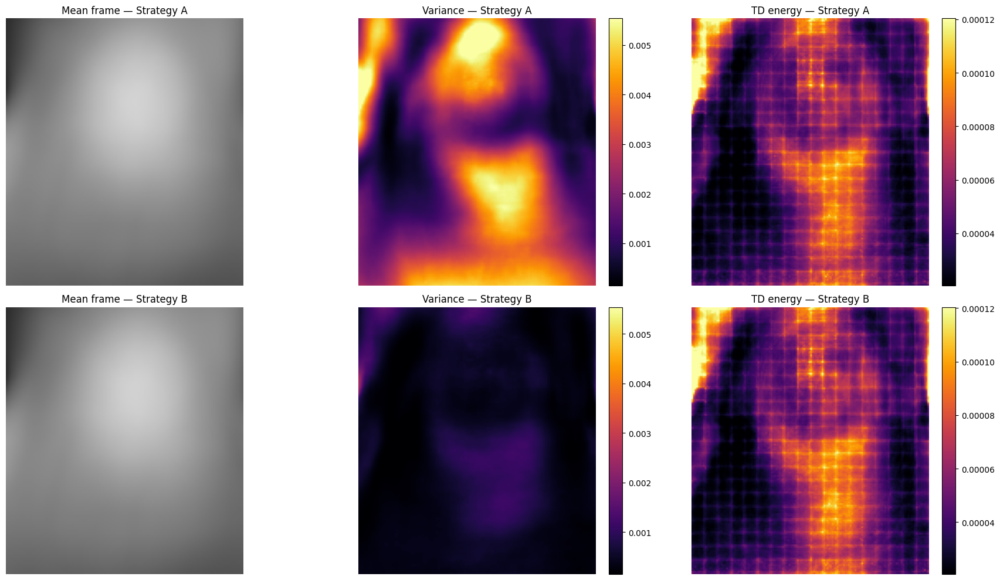

Crop box used (x0, x1, y0, y1): (56, 200, 15, 177)


In [ ]:
# ============================================================
# Block 18: Cropped compare of Strategy A vs Strategy B
# ============================================================

def combined_robust_limits(img1, img2, low_pct=2, high_pct=99):
    vals = np.concatenate([img1.ravel(), img2.ravel()])
    vmin = np.percentile(vals, low_pct)
    vmax = np.percentile(vals, high_pct)
    if vmax <= vmin:
        vmin = vals.min()
        vmax = vals.max()
    return vmin, vmax

meanA_crop, crop_box = crop_by_fraction(mean_A, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
varA_crop, _ = crop_by_fraction(var_A,  XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
tdA_crop,  _ = crop_by_fraction(td_A,   XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

meanB_crop, _ = crop_by_fraction(mean_B, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
varB_crop, _ = crop_by_fraction(var_B,   XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
tdB_crop,  _ = crop_by_fraction(td_B,    XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

var_vmin, var_vmax = combined_robust_limits(varA_crop, varB_crop, low_pct=2, high_pct=99)
td_vmin, td_vmax   = combined_robust_limits(tdA_crop, tdB_crop,   low_pct=2, high_pct=99)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0,0].imshow(meanA_crop, cmap="gray", vmin=0, vmax=1)
axes[0,0].set_title("Mean frame — Strategy A")
axes[0,0].axis("off")

im1 = axes[0,1].imshow(varA_crop, cmap="inferno", vmin=var_vmin, vmax=var_vmax)
axes[0,1].set_title("Variance — Strategy A")
axes[0,1].axis("off")
plt.colorbar(im1, ax=axes[0,1], fraction=0.046, pad=0.04)

im2 = axes[0,2].imshow(tdA_crop, cmap="inferno", vmin=td_vmin, vmax=td_vmax)
axes[0,2].set_title("TD energy — Strategy A")
axes[0,2].axis("off")
plt.colorbar(im2, ax=axes[0,2], fraction=0.046, pad=0.04)

axes[1,0].imshow(meanB_crop, cmap="gray", vmin=0, vmax=1)
axes[1,0].set_title("Mean frame — Strategy B")
axes[1,0].axis("off")

im3 = axes[1,1].imshow(varB_crop, cmap="inferno", vmin=var_vmin, vmax=var_vmax)
axes[1,1].set_title("Variance — Strategy B")
axes[1,1].axis("off")
plt.colorbar(im3, ax=axes[1,1], fraction=0.046, pad=0.04)

im4 = axes[1,2].imshow(tdB_crop, cmap="inferno", vmin=td_vmin, vmax=td_vmax)
axes[1,2].set_title("TD energy — Strategy B")
axes[1,2].axis("off")
plt.colorbar(im4, ax=axes[1,2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("Crop box used (x0, x1, y0, y1):", crop_box)

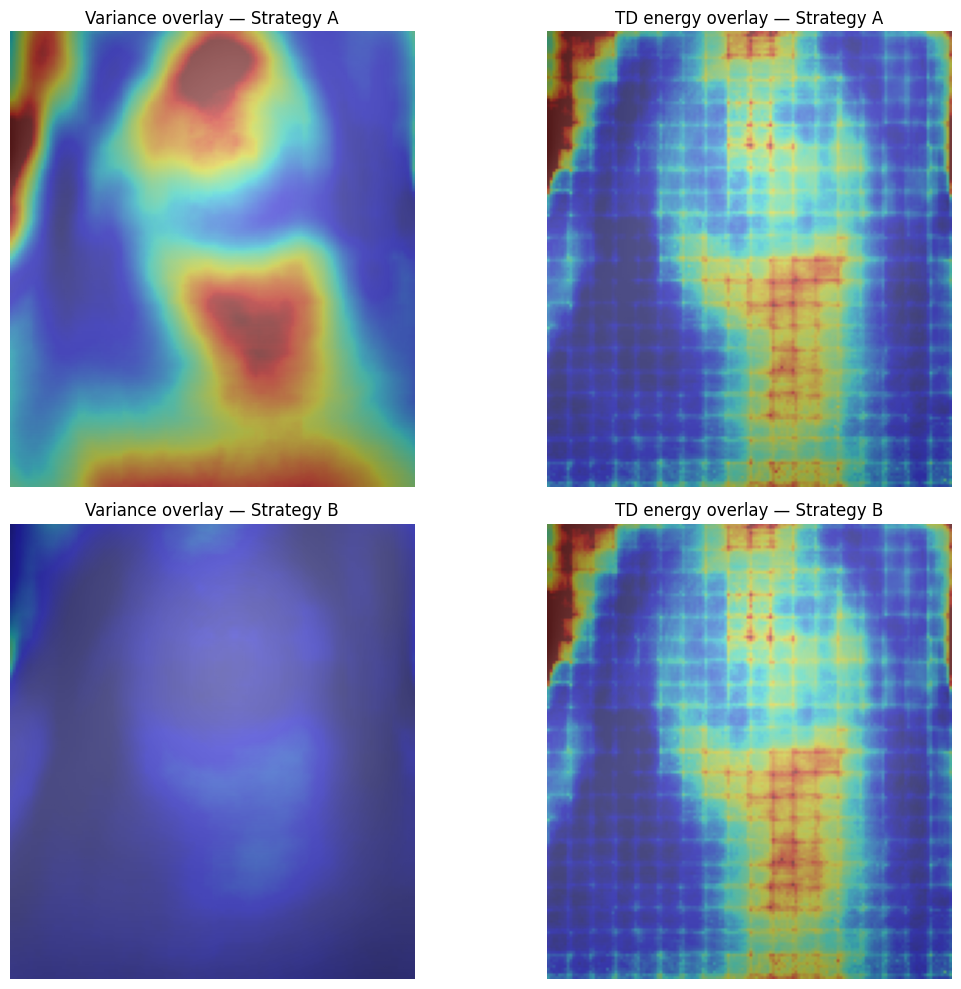

In [ ]:
# ============================================================
# Block 19: Overlay compare for Strategy A vs Strategy B
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0,0].imshow(meanA_crop, cmap="gray", vmin=0, vmax=1)
axes[0,0].imshow(varA_crop, cmap="jet", alpha=0.45, vmin=var_vmin, vmax=var_vmax)
axes[0,0].set_title("Variance overlay — Strategy A")
axes[0,0].axis("off")

axes[0,1].imshow(meanA_crop, cmap="gray", vmin=0, vmax=1)
axes[0,1].imshow(tdA_crop, cmap="jet", alpha=0.45, vmin=td_vmin, vmax=td_vmax)
axes[0,1].set_title("TD energy overlay — Strategy A")
axes[0,1].axis("off")

axes[1,0].imshow(meanB_crop, cmap="gray", vmin=0, vmax=1)
axes[1,0].imshow(varB_crop, cmap="jet", alpha=0.45, vmin=var_vmin, vmax=var_vmax)
axes[1,0].set_title("Variance overlay — Strategy B")
axes[1,0].axis("off")

axes[1,1].imshow(meanB_crop, cmap="gray", vmin=0, vmax=1)
axes[1,1].imshow(tdB_crop, cmap="jet", alpha=0.45, vmin=td_vmin, vmax=td_vmax)
axes[1,1].set_title("TD energy overlay — Strategy B")
axes[1,1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Block 20: Prepare stacked SVD across all clips
# ============================================================

# For stacked SVD, we center each clip separately, then concatenate columns.
# This keeps focus on within-clip dynamics rather than clip-to-clip offsets.

DO_CLIP_STANDARDIZE = False   # set True later if you want each clip to contribute more equally in amplitude

Xc_list = []
clip_boundaries = [0]
clip_names = []
clip_lengths = []

for c in clips_data:
    frames_i = c["frames"]              # (T, H, W)
    T_i = c["T"]

    Xi = frames_i.reshape(T_i, H*W).T   # (P, T_i)
    mu_i = np.mean(Xi, axis=1, keepdims=True)
    Xci = Xi - mu_i

    if DO_CLIP_STANDARDIZE:
        s_i = np.std(Xci)
        if s_i > 1e-8:
            Xci = Xci / s_i

    Xc_list.append(Xci)
    clip_names.append(c["name"])
    clip_lengths.append(T_i)
    clip_boundaries.append(clip_boundaries[-1] + T_i)

X_stack = np.concatenate(Xc_list, axis=1)   # (P, total_frames)

print("X_stack shape:", X_stack.shape)
print("Number of clips stacked:", len(clip_names))
print("Clip boundaries:", clip_boundaries[:5], "...", clip_boundaries[-5:])

X_stack shape: (49152, 1280)
Number of clips stacked: 20
Clip boundaries: [0, 49, 112, 165, 215] ... [966, 1025, 1083, 1184, 1280]


First mode count reaching cumulative threshold: 69
Selected modes (0-based): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Selected modes (1-based): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


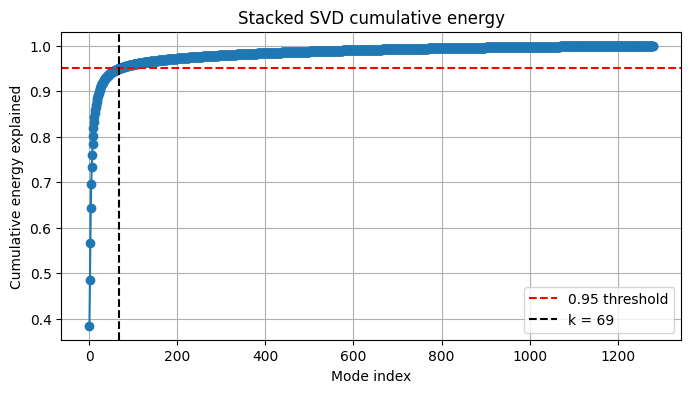

Mode 1: singular value = 105.9838, energy ratio = 0.3847
Mode 2: singular value = 54.1179, energy ratio = 0.1003
Mode 3: singular value = 48.8151, energy ratio = 0.0816
Mode 4: singular value = 47.3065, energy ratio = 0.0767
Mode 5: singular value = 39.2954, energy ratio = 0.0529
Mode 6: singular value = 32.6341, energy ratio = 0.0365
Mode 7: singular value = 28.2827, energy ratio = 0.0274
Mode 8: singular value = 26.0404, energy ratio = 0.0232
Mode 9: singular value = 23.6118, energy ratio = 0.0191
Mode 10: singular value = 21.6320, energy ratio = 0.0160
Mode 11: singular value = 19.6235, energy ratio = 0.0132
Mode 12: singular value = 18.1532, energy ratio = 0.0113


In [ ]:
# ============================================================
# Block 21: Run stacked SVD and select modes
# ============================================================

U_stack, S_stack, VT_stack = np.linalg.svd(X_stack, full_matrices=False)

energy = S_stack**2
energy_ratio = energy / np.sum(energy)
cum_energy = np.cumsum(energy_ratio)

# ---- mode-selection settings ----
CUM_ENERGY_THRESHOLD = 0.95   # e.g. keep enough modes to explain 95% energy
MAX_MODES_TO_SHOW    = 15      # safety cap for plotting
MIN_MODE_ENERGY      = 0.01    # e.g. 0.01 means only modes with >=1% energy

k_cum = np.searchsorted(cum_energy, CUM_ENERGY_THRESHOLD) + 1

selected_modes = []
for k in range(k_cum):
    if energy_ratio[k] >= MIN_MODE_ENERGY:
        selected_modes.append(k)

selected_modes = selected_modes[:MAX_MODES_TO_SHOW]

print("First mode count reaching cumulative threshold:", k_cum)
print("Selected modes (0-based):", selected_modes)
print("Selected modes (1-based):", [k+1 for k in selected_modes])

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(S_stack)+1), cum_energy, marker="o")
plt.axhline(CUM_ENERGY_THRESHOLD, color="r", linestyle="--", label=f"{CUM_ENERGY_THRESHOLD:.2f} threshold")
plt.axvline(k_cum, color="k", linestyle="--", label=f"k = {k_cum}")
plt.xlabel("Mode index")
plt.ylabel("Cumulative energy explained")
plt.title("Stacked SVD cumulative energy")
plt.grid(True)
plt.legend()
plt.show()

for k in range(min(12, len(S_stack))):
    print(f"Mode {k+1}: singular value = {S_stack[k]:.4f}, energy ratio = {energy_ratio[k]:.4f}")

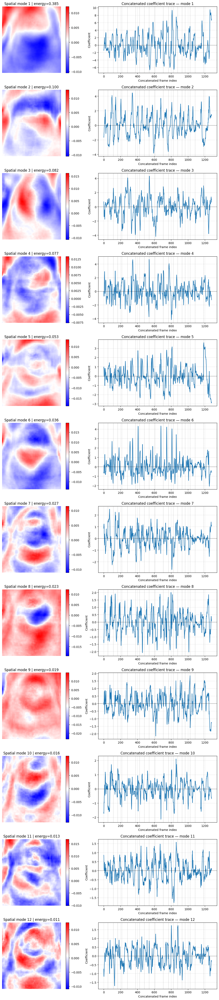

In [ ]:
# ============================================================
# Block 22: Plot selected stacked modes + time traces
# ============================================================

def crop_mode_image(img):
    img_crop, _ = crop_by_fraction(img, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
    return img_crop

num_modes = len(selected_modes)

if num_modes == 0:
    raise ValueError("No modes selected. Try lowering MIN_MODE_ENERGY or increasing the cumulative threshold.")

fig, axes = plt.subplots(num_modes, 2, figsize=(13, 4*num_modes))

if num_modes == 1:
    axes = np.array([axes])

for row, k in enumerate(selected_modes):
    mode_img = U_stack[:, k].reshape(H, W)
    mode_img_crop = crop_mode_image(mode_img)

    coeff_k = S_stack[k] * VT_stack[k, :]   # modal coefficient trace across concatenated clips

    im = axes[row, 0].imshow(mode_img_crop, cmap="bwr")
    axes[row, 0].set_title(f"Spatial mode {k+1} | energy={energy_ratio[k]:.3f}")
    axes[row, 0].axis("off")
    plt.colorbar(im, ax=axes[row, 0], fraction=0.046, pad=0.04)

    axes[row, 1].plot(coeff_k, linewidth=1.5)
    axes[row, 1].axhline(0, color="k", linewidth=0.8, alpha=0.5)

    for b in clip_boundaries[1:-1]:
        axes[row, 1].axvline(b - 0.5, color="k", linestyle="--", linewidth=0.6, alpha=0.35)

    axes[row, 1].set_title(f"Concatenated coefficient trace — mode {k+1}")
    axes[row, 1].set_xlabel("Concatenated frame index")
    axes[row, 1].set_ylabel("Coefficient")
    axes[row, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

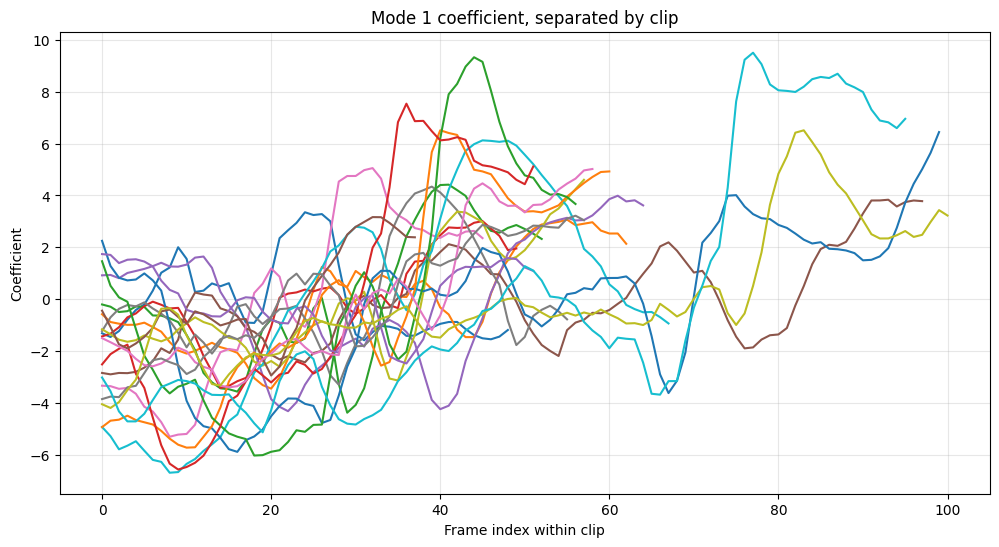

In [ ]:
# ============================================================
# Block 23: Optional per-clip trace view for one chosen mode
# ============================================================

MODE_TO_INSPECT = selected_modes[0]   # change if you want another selected mode

coeff_full = S_stack[MODE_TO_INSPECT] * VT_stack[MODE_TO_INSPECT, :]

plt.figure(figsize=(12, 6))

start = 0
for i, T_i in enumerate(clip_lengths):
    end = start + T_i
    coeff_i = coeff_full[start:end]
    plt.plot(np.arange(T_i), coeff_i, label=f"clip {i}")
    start = end

plt.xlabel("Frame index within clip")
plt.ylabel("Coefficient")
plt.title(f"Mode {MODE_TO_INSPECT+1} coefficient, separated by clip")
plt.grid(True, alpha=0.3)

# Usually too many legends if 20 clips; uncomment only if needed
# plt.legend(ncol=2, fontsize=8)

plt.show()

In [ ]:
# ============================================================
# New Analysis with all silent speech data available
# ============================================================

In [ ]:
# ============================================================
# Block 1: Imports and top-level config
# ============================================================
import os
import json
import gc
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# Optional UMAP
try:
    import umap.umap_ as umap
    HAS_UMAP = True
except Exception:
    HAS_UMAP = False
    print("UMAP not found. Later, if needed: !pip install umap-learn")

# Optional: only needed in Colab
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- USER CONFIG ----------------
#ROOT_FOLDER = ""   # paste the shortcut folder path in My Drive
#OUTPUT_DIR = "/content/drive/My Drive/ir_ssi_analysis_outputs"

VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv")
GRAYSCALE = True
FRAME_STRIDE = 1
MAX_FRAMES_PER_CLIP = None     # e.g. 80 if you want a cap
RESIZE_TO = None               # e.g. (256, 192), else None

# Cropping for display only
XMIN_FRAC, XMAX_FRAC = 0.18, 0.82
YMIN_FRAC, YMAX_FRAC = 0.08, 0.92

# Metadata parsing from relative folder path
# Example: if rel_dir = subject/word, then SUBJECT_LEVEL=0, WORD_LEVEL=1
# Adjust after previewing Block 3
SUBJECT_LEVEL = 0
WORD_LEVEL = 1

# Truncated SVD / PCA settings
N_COMPONENTS = 40             # adjust later if needed
FIT_BATCH_ROWS = 400          # rows = frames accumulated before partial_fit
PLOT_FIRST_MODES = 8

# Clustering settings
TSNE_PERPLEXITY = 20
TSNE_RANDOM_STATE = 42
UMAP_RANDOM_STATE = 42

In [ ]:
# ============================================================
# Block 2-4
# Recursive scan block — no file-type filtering at all
# Assumption:
#   ROOT_FOLDER/
#       Subj1-Banana/
#           20 files
#       Subj1-engineering/
#           20 files
#       ...
# and those files are the videos you want.
# ============================================================

import os
from pathlib import Path
from collections import Counter
import pandas as pd

# Optional Colab import
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---------------- USER CONFIG ----------------
ROOT_FOLDER = "/content/drive/My Drive/Centre_align_cropped"

# ---------------- MOUNT DRIVE ----------------
if IN_COLAB:
    if not os.path.exists("/content/drive"):
        drive.mount("/content/drive")
    else:
        print("Drive path already exists.")
else:
    print("Not running in Colab.")

# ---------------- PATH CHECK ----------------
root = Path(ROOT_FOLDER)

if not root.exists():
    raise FileNotFoundError(f"ROOT_FOLDER not found:\n{ROOT_FOLDER}")

if not root.is_dir():
    raise ValueError(f"ROOT_FOLDER is not a directory:\n{ROOT_FOLDER}")

print("ROOT_FOLDER exists:")
print(ROOT_FOLDER)

print("\nImmediate children under ROOT_FOLDER:")
children = sorted(list(root.iterdir()), key=lambda p: p.name.lower())
for p in children[:50]:
    kind = "DIR " if p.is_dir() else "FILE"
    print(f" - [{kind}] {p.name}")
if len(children) > 50:
    print(" ...")

# ---------------- RECURSIVE FILE DISCOVERY ----------------
# No suffix / extension filtering at all
all_files = sorted([p for p in root.rglob("*") if p.is_file()])

print(f"\nTotal files found recursively: {len(all_files)}")

if len(all_files) == 0:
    raise ValueError("No files found anywhere under ROOT_FOLDER.")

# ---------------- BUILD MANIFEST ----------------
records = []

for fp in all_files:
    rel_path = fp.relative_to(root)
    rel_parts = rel_path.parts[:-1]   # folder parts only
    rel_dir = rel_path.parent.as_posix()
    parent_folder = fp.parent.name    # expected like Subj1-Banana

    # parse subject / word from immediate parent folder
    if "-" in parent_folder:
        subject, word = parent_folder.split("-", 1)
    else:
        subject, word = "", ""

    rec = {
        "abs_path": str(fp),
        "rel_path": rel_path.as_posix(),
        "rel_dir": rel_dir,
        "parent_folder": parent_folder,
        "file_name": fp.name,
        "subject": subject,
        "word": word,
        "folder_depth": len(rel_parts),
    }

    for i, part in enumerate(rel_parts):
        rec[f"path_level_{i}"] = part

    records.append(rec)

manifest_df = pd.DataFrame(records).sort_values("rel_path").reset_index(drop=True)

# ---------------- QUICK SANITY CHECKS ----------------
print("\nManifest built successfully.")
print("Number of file rows:", len(manifest_df))

print("\nUnique parent folders:")
for x in manifest_df["parent_folder"].drop_duplicates().tolist():
    print(" -", x)

print("\nFiles per parent folder:")
folder_counts = manifest_df["parent_folder"].value_counts().sort_index()
display(folder_counts)

print("\nPreview:")
display(manifest_df.head(20))

# ---------------- SAVE ----------------
manifest_csv = os.path.join(ROOT_FOLDER, "file_manifest_preview.csv")
manifest_df.to_csv(manifest_csv, index=False)

print("\nSaved manifest preview to:")
print(manifest_csv)

Mounted at /content/drive
ROOT_FOLDER exists:
/content/drive/My Drive/Centre_align_cropped

Immediate children under ROOT_FOLDER:
 - [FILE] file_manifest_preview.csv
 - [DIR ] Subj1-Banana
 - [DIR ] Subj1-engineering
 - [DIR ] Subj1-sports
 - [DIR ] Subj1-tomorrow
 - [DIR ] Subj1-yesterday
 - [DIR ] Subj2-Banana
 - [DIR ] Subj2-engineering
 - [DIR ] Subj2-sports
 - [DIR ] Subj2-tomorrow
 - [DIR ] Subj2-yesterday
 - [DIR ] Subj4-Banana
 - [DIR ] Subj4-engineering
 - [DIR ] Subj4-sports
 - [DIR ] Subj4-tomorrow
 - [DIR ] Subj4-yesterday
 - [DIR ] Subj6-Banana
 - [DIR ] Subj6-engineering
 - [DIR ] Subj6-sports
 - [DIR ] Subj6-tomorrow
 - [DIR ] Subj6-yesterday

Total files found recursively: 401

Manifest built successfully.
Number of file rows: 401

Unique parent folders:
 - Subj1-Banana
 - Subj1-engineering
 - Subj1-sports
 - Subj1-tomorrow
 - Subj1-yesterday
 - Subj2-Banana
 - Subj2-engineering
 - Subj2-sports
 - Subj2-tomorrow
 - Subj2-yesterday
 - Subj4-Banana
 - Subj4-engineering
 -

,count
parent_folder,
Centre_align_cropped,1
Subj1-Banana,20
Subj1-engineering,20
Subj1-sports,20
Subj1-tomorrow,20
Subj1-yesterday,20
Subj2-Banana,20
Subj2-engineering,20
Subj2-sports,20



Preview:


,abs_path,rel_path,rel_dir,parent_folder,file_name,subject,word,folder_depth,path_level_0
0,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana10_crop.mp4,Subj1,Banana,1,Subj1-Banana
1,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana11_crop.mp4,Subj1,Banana,1,Subj1-Banana
2,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana12_crop.mp4,Subj1,Banana,1,Subj1-Banana
3,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana13_crop.mp4,Subj1,Banana,1,Subj1-Banana
4,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana14_crop.mp4,Subj1,Banana,1,Subj1-Banana
5,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana15_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana15_crop.mp4,Subj1,Banana,1,Subj1-Banana
6,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana16_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana16_crop.mp4,Subj1,Banana,1,Subj1-Banana
7,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana17_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana17_crop.mp4,Subj1,Banana,1,Subj1-Banana
8,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana18_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana18_crop.mp4,Subj1,Banana,1,Subj1-Banana
9,/content/drive/My Drive/Centre_align_cropped/S...,Subj1-Banana/Copy of Subj1-banana19_crop.mp4,Subj1-Banana,Subj1-Banana,Copy of Subj1-banana19_crop.mp4,Subj1,Banana,1,Subj1-Banana



Saved manifest preview to:
/content/drive/My Drive/Centre_align_cropped/file_manifest_preview.csv


In [ ]:
# ============================================================
# Block 5: Helpers
# ============================================================
def load_video_frames(video_path, grayscale=True, resize_to=None, frame_stride=1, max_frames=None):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")

    frames = []
    frame_count = 0
    kept_count = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_count % frame_stride == 0:
            if grayscale:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

            if resize_to is not None:
                frame = cv2.resize(frame, resize_to)

            frame = frame.astype(np.float32) / 255.0
            frames.append(frame)
            kept_count += 1

            if max_frames is not None and kept_count >= max_frames:
                break

        frame_count += 1

    cap.release()

    if len(frames) == 0:
        raise ValueError(f"No frames loaded from {video_path}")

    return np.stack(frames, axis=0)   # (T, H, W)

def crop_by_fraction(img, xmin_frac, xmax_frac, ymin_frac, ymax_frac):
    H, W = img.shape
    x0 = int(np.floor(W * xmin_frac))
    x1 = int(np.ceil(W * xmax_frac))
    y0 = int(np.floor(H * ymin_frac))
    y1 = int(np.ceil(H * ymax_frac))
    return img[y0:y1, x0:x1], (x0, x1, y0, y1)

def robust_limits(img, low_pct=2, high_pct=99):
    vmin = np.percentile(img, low_pct)
    vmax = np.percentile(img, high_pct)
    if vmax <= vmin:
        vmin = img.min()
        vmax = img.max()
    return vmin, vmax

In [ ]:
# ============================================================
# Block 6: Full-dataset Strategy B pooled mean / variance / TD energy
# ============================================================
sum_mean = None
sum_var = None
sum_td = None

valid_count = 0
clip_summary = []

for i, row in manifest_df.iterrows():
    try:
        frames = load_video_frames(
            row["abs_path"],
            grayscale=GRAYSCALE,
            resize_to=RESIZE_TO,
            frame_stride=FRAME_STRIDE,
            max_frames=MAX_FRAMES_PER_CLIP
        )

        T, H, W = frames.shape
        if T < 2:
            print(f"Skipping {row['rel_path']} because T < 2")
            continue

        mean_i = np.mean(frames, axis=0)
        var_i = np.var(frames, axis=0, ddof=1)
        td_i = np.mean(np.diff(frames, axis=0)**2, axis=0)

        if sum_mean is None:
            sum_mean = np.zeros_like(mean_i, dtype=np.float64)
            sum_var = np.zeros_like(var_i, dtype=np.float64)
            sum_td = np.zeros_like(td_i, dtype=np.float64)

        sum_mean += mean_i
        sum_var += var_i
        sum_td += td_i
        valid_count += 1

        clip_summary.append({
            "rel_path": row["rel_path"],
            "subject": row["subject"],
            "word": row["word"],
            "n_frames": T
        })

        if (i + 1) % 20 == 0:
            print(f"Processed {i+1}/{len(manifest_df)} clips")

        del frames
        gc.collect()

    except Exception as e:
        print("FAILED:", row["rel_path"], "|", e)

if valid_count == 0:
    raise ValueError("No valid clips processed.")

mean_B = sum_mean / valid_count
var_B = sum_var / valid_count
td_B = sum_td / valid_count

print("Valid clips used:", valid_count)
print("Global map shape:", mean_B.shape)


Processed 20/400 clips
Processed 40/400 clips
Processed 60/400 clips
Processed 80/400 clips
Processed 100/400 clips
Processed 120/400 clips
Processed 140/400 clips
Processed 160/400 clips
Processed 180/400 clips
Processed 200/400 clips
Processed 220/400 clips
Processed 240/400 clips
Processed 260/400 clips
Processed 280/400 clips
Processed 300/400 clips
Processed 320/400 clips
Processed 340/400 clips
Processed 360/400 clips
Processed 380/400 clips
Processed 400/400 clips
Valid clips used: 400
Global map shape: (192, 256)


In [ ]:
OUTPUT_DIR = '/content/drive/My Drive/Centre_align_cropped_output'
maps_npz = os.path.join(OUTPUT_DIR, "global_strategyB_maps.npz")
np.savez_compressed(
    maps_npz,
    mean_B=mean_B.astype(np.float32),
    var_B=var_B.astype(np.float32),
    td_B=td_B.astype(np.float32)
)
print("Saved:", maps_npz)

clip_summary_df = pd.DataFrame(clip_summary)
clip_summary_csv = os.path.join(OUTPUT_DIR, "clip_summary.csv")
clip_summary_df.to_csv(clip_summary_csv, index=False)
print("Saved:", clip_summary_csv)

Saved: /content/drive/My Drive/Centre_align_cropped_output/global_strategyB_maps.npz
Saved: /content/drive/My Drive/Centre_align_cropped_output/clip_summary.csv


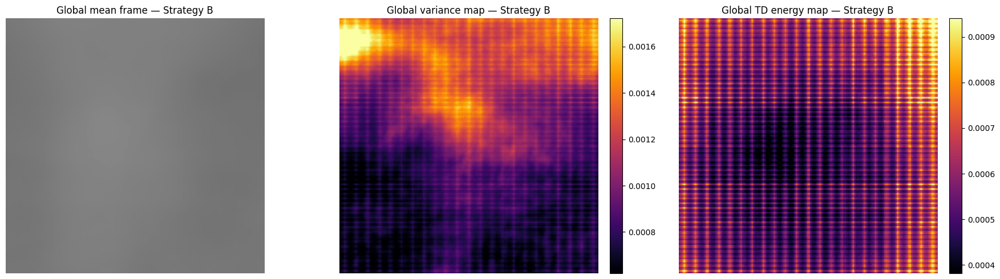

Crop box: (46, 210, 15, 177)


In [ ]:
# ============================================================
# Block 7: Display global Strategy B maps
# ============================================================
mean_crop, crop_box = crop_by_fraction(mean_B, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
var_crop, _ = crop_by_fraction(var_B, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)
td_crop, _ = crop_by_fraction(td_B, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

var_vmin, var_vmax = robust_limits(var_crop, 2, 99)
td_vmin, td_vmax = robust_limits(td_crop, 2, 99)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(mean_crop, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Global mean frame — Strategy B")
axes[0].axis("off")

im1 = axes[1].imshow(var_crop, cmap="inferno", vmin=var_vmin, vmax=var_vmax)
axes[1].set_title("Global variance map — Strategy B")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(td_crop, cmap="inferno", vmin=td_vmin, vmax=td_vmax)
axes[2].set_title("Global TD energy map — Strategy B")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("Crop box:", crop_box)

Processed 20/400 clips
Processed 40/400 clips
Processed 60/400 clips
Processed 80/400 clips
Processed 100/400 clips
Processed 120/400 clips
Processed 140/400 clips
Processed 160/400 clips
Processed 180/400 clips
Processed 200/400 clips
Processed 220/400 clips
Processed 240/400 clips
Processed 260/400 clips
Processed 280/400 clips
Processed 300/400 clips
Processed 320/400 clips
Processed 340/400 clips
Processed 360/400 clips
Processed 380/400 clips
Processed 400/400 clips
Valid clips used: 400
Smoothed map shape: (192, 256)
Saved: /content/drive/My Drive/Centre_align_cropped_output/global_strategyB_maps_smoothed_k3.npz
Saved: /content/drive/My Drive/Centre_align_cropped_output/clip_summary_smoothed_k3.csv


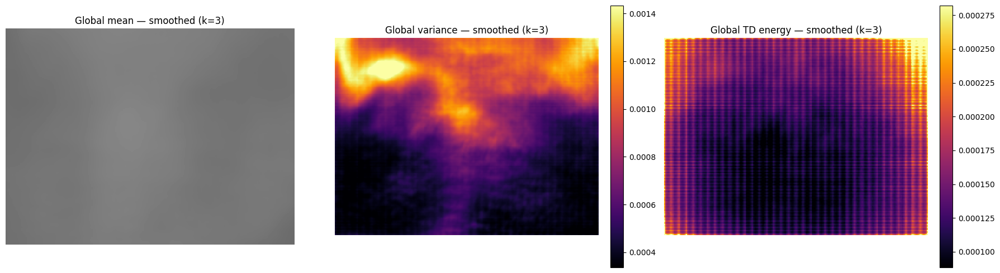

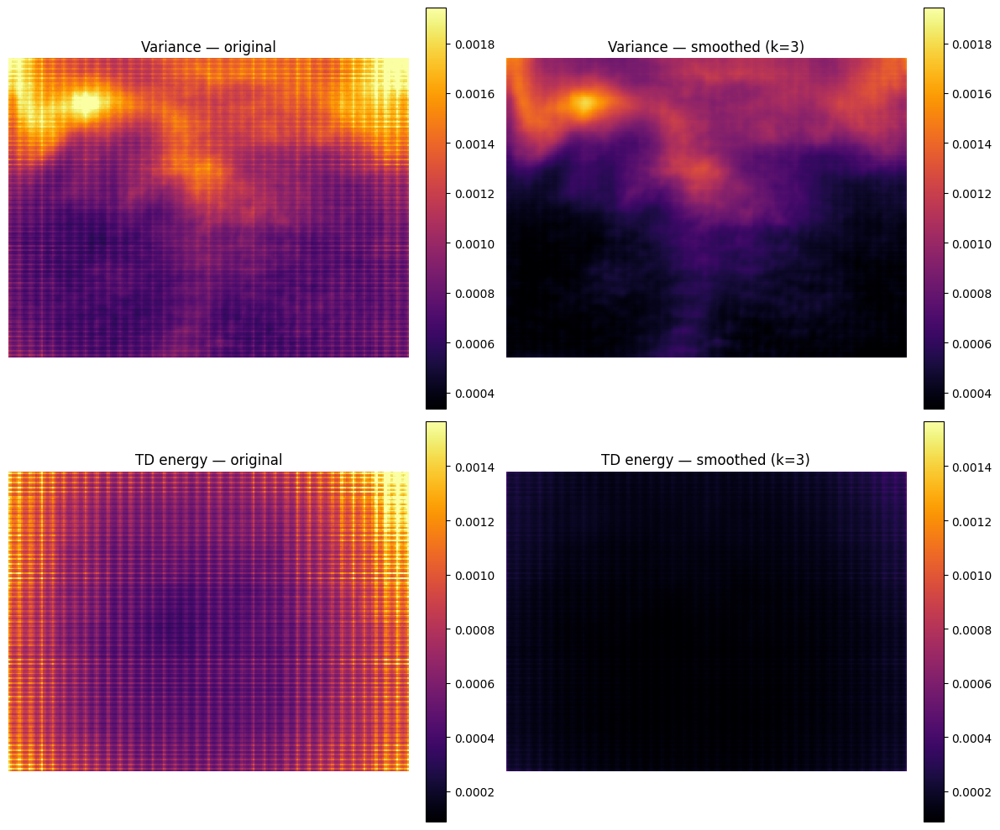

In [ ]:
# ============================================================
# Remedy block:
# Recompute global Strategy B maps after light spatial smoothing
# No cropping. Full-frame display only.
# ============================================================

import os
import gc
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ---------------- USER SETTINGS ----------------
SMOOTH_KERNEL = 3      # try 3 first; if needed later, test 5
SMOOTH_SIGMA = 0       # 0 lets OpenCV choose from kernel size
SAVE_SMOOTHED_MAPS = True

# Optional output folder if not already defined
try:
    OUTPUT_DIR
except NameError:
    OUTPUT_DIR = "/content/drive/My Drive/Centre_align_cropped_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------------- RECOMPUTE GLOBAL STRATEGY B MAPS ----------------
sum_mean_s = None
sum_var_s = None
sum_td_s = None

valid_count_s = 0
clip_summary_s = []

for i, row in manifest_df.iterrows():
    try:
        frames = load_video_frames(
            row["abs_path"],
            grayscale=GRAYSCALE,
            resize_to=RESIZE_TO,
            frame_stride=FRAME_STRIDE,
            max_frames=MAX_FRAMES_PER_CLIP
        )  # shape: (T, H, W)

        T, H, W = frames.shape
        if T < 2:
            print(f"Skipping {row['rel_path']} because T < 2")
            continue

        # Apply small Gaussian blur frame by frame
        frames_s = np.empty_like(frames, dtype=np.float32)
        for t in range(T):
            frames_s[t] = cv2.GaussianBlur(
                frames[t],
                (SMOOTH_KERNEL, SMOOTH_KERNEL),
                SMOOTH_SIGMA
            )

        mean_i_s = np.mean(frames_s, axis=0)
        var_i_s  = np.var(frames_s, axis=0, ddof=1)
        td_i_s   = np.mean(np.diff(frames_s, axis=0)**2, axis=0)

        if sum_mean_s is None:
            sum_mean_s = np.zeros_like(mean_i_s, dtype=np.float64)
            sum_var_s  = np.zeros_like(var_i_s,  dtype=np.float64)
            sum_td_s   = np.zeros_like(td_i_s,   dtype=np.float64)

        sum_mean_s += mean_i_s
        sum_var_s  += var_i_s
        sum_td_s   += td_i_s
        valid_count_s += 1

        clip_summary_s.append({
            "rel_path": row["rel_path"],
            "subject": row.get("subject", ""),
            "word": row.get("word", ""),
            "n_frames": T
        })

        if (i + 1) % 20 == 0:
            print(f"Processed {i+1}/{len(manifest_df)} clips")

        del frames, frames_s
        gc.collect()

    except Exception as e:
        print("FAILED:", row["rel_path"], "|", e)

if valid_count_s == 0:
    raise ValueError("No valid clips processed in smoothed-map pass.")

mean_B_s = sum_mean_s / valid_count_s
var_B_s  = sum_var_s  / valid_count_s
td_B_s   = sum_td_s   / valid_count_s

print("Valid clips used:", valid_count_s)
print("Smoothed map shape:", mean_B_s.shape)

# ---------------- SAVE ----------------
if SAVE_SMOOTHED_MAPS:
    maps_npz_s = os.path.join(
        OUTPUT_DIR,
        f"global_strategyB_maps_smoothed_k{SMOOTH_KERNEL}.npz"
    )
    np.savez_compressed(
        maps_npz_s,
        mean_B_s=mean_B_s.astype(np.float32),
        var_B_s=var_B_s.astype(np.float32),
        td_B_s=td_B_s.astype(np.float32),
        smooth_kernel=np.array([SMOOTH_KERNEL], dtype=np.int32),
        smooth_sigma=np.array([SMOOTH_SIGMA], dtype=np.float32),
    )
    print("Saved:", maps_npz_s)

    clip_summary_s_df = pd.DataFrame(clip_summary_s)
    clip_summary_s_csv = os.path.join(
        OUTPUT_DIR,
        f"clip_summary_smoothed_k{SMOOTH_KERNEL}.csv"
    )
    clip_summary_s_df.to_csv(clip_summary_s_csv, index=False)
    print("Saved:", clip_summary_s_csv)

# ---------------- PLOT: smoothed maps only ----------------
def robust_limits(img, low_pct=2, high_pct=99):
    vmin = np.percentile(img, low_pct)
    vmax = np.percentile(img, high_pct)
    if vmax <= vmin:
        vmin = img.min()
        vmax = img.max()
    return vmin, vmax

var_vmin_s, var_vmax_s = robust_limits(var_B_s, 2, 99)
td_vmin_s, td_vmax_s   = robust_limits(td_B_s, 2, 99)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].imshow(mean_B_s, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
axes[0].set_title(f"Global mean — smoothed (k={SMOOTH_KERNEL})")
axes[0].axis("off")

im1 = axes[1].imshow(var_B_s, cmap="inferno", vmin=var_vmin_s, vmax=var_vmax_s, interpolation="nearest")
axes[1].set_title(f"Global variance — smoothed (k={SMOOTH_KERNEL})")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(td_B_s, cmap="inferno", vmin=td_vmin_s, vmax=td_vmax_s, interpolation="nearest")
axes[2].set_title(f"Global TD energy — smoothed (k={SMOOTH_KERNEL})")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# ---------------- OPTIONAL SIDE-BY-SIDE COMPARISON ----------------
if all(name in globals() for name in ["mean_B", "var_B", "td_B"]):
    var_vmin_cmp = min(np.percentile(var_B, 2), np.percentile(var_B_s, 2))
    var_vmax_cmp = max(np.percentile(var_B, 99), np.percentile(var_B_s, 99))
    td_vmin_cmp  = min(np.percentile(td_B, 2), np.percentile(td_B_s, 2))
    td_vmax_cmp  = max(np.percentile(td_B, 99), np.percentile(td_B_s, 99))

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    im1 = axes[0,0].imshow(var_B, cmap="inferno", vmin=var_vmin_cmp, vmax=var_vmax_cmp, interpolation="nearest")
    axes[0,0].set_title("Variance — original")
    axes[0,0].axis("off")
    plt.colorbar(im1, ax=axes[0,0], fraction=0.046, pad=0.04)

    im2 = axes[0,1].imshow(var_B_s, cmap="inferno", vmin=var_vmin_cmp, vmax=var_vmax_cmp, interpolation="nearest")
    axes[0,1].set_title(f"Variance — smoothed (k={SMOOTH_KERNEL})")
    axes[0,1].axis("off")
    plt.colorbar(im2, ax=axes[0,1], fraction=0.046, pad=0.04)

    im3 = axes[1,0].imshow(td_B, cmap="inferno", vmin=td_vmin_cmp, vmax=td_vmax_cmp, interpolation="nearest")
    axes[1,0].set_title("TD energy — original")
    axes[1,0].axis("off")
    plt.colorbar(im3, ax=axes[1,0], fraction=0.046, pad=0.04)

    im4 = axes[1,1].imshow(td_B_s, cmap="inferno", vmin=td_vmin_cmp, vmax=td_vmax_cmp, interpolation="nearest")
    axes[1,1].set_title(f"TD energy — smoothed (k={SMOOTH_KERNEL})")
    axes[1,1].axis("off")
    plt.colorbar(im4, ax=axes[1,1], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()
else:
    print("Original mean_B / var_B / td_B not found in memory, so only smoothed maps were shown.")

In [ ]:
# ============================================================
# Block 8: IncrementalPCA fit pass on clip-demeaned frames
# ============================================================
ipca = IncrementalPCA(n_components=N_COMPONENTS)

pending_batches = []
pending_rows = 0
fit_calls = 0
frame_size = None

for i, row in manifest_df.iterrows():
    try:
        frames = load_video_frames(
            row["abs_path"],
            grayscale=GRAYSCALE,
            resize_to=RESIZE_TO,
            frame_stride=FRAME_STRIDE,
            max_frames=MAX_FRAMES_PER_CLIP
        )

        T, H, W = frames.shape
        X = frames.reshape(T, H * W).astype(np.float32)

        # per-clip de-mean
        Xc = X - np.mean(X, axis=0, keepdims=True)

        if frame_size is None:
            frame_size = H * W

        pending_batches.append(Xc)
        pending_rows += Xc.shape[0]

        if pending_rows >= FIT_BATCH_ROWS:
            batch = np.vstack(pending_batches)

            if batch.shape[0] >= N_COMPONENTS:
                ipca.partial_fit(batch)
                fit_calls += 1
                print(f"partial_fit #{fit_calls} | batch rows = {batch.shape[0]}")
            else:
                print(f"Skipping batch with too few rows for fit: {batch.shape[0]}")

            pending_batches = []
            pending_rows = 0

        del frames, X, Xc
        gc.collect()

    except Exception as e:
        print("FAILED during fit:", row["rel_path"], "|", e)

# final residual batch
if len(pending_batches) > 0:
    batch = np.vstack(pending_batches)
    if batch.shape[0] >= N_COMPONENTS:
        ipca.partial_fit(batch)
        fit_calls += 1
        print(f"final partial_fit #{fit_calls} | batch rows = {batch.shape[0]}")
    else:
        print(f"Residual batch too small for final partial_fit: {batch.shape[0]}")

print("Total fit calls:", fit_calls)
print("Components shape:", ipca.components_.shape)

partial_fit #1 | batch rows = 481
partial_fit #2 | batch rows = 409
partial_fit #3 | batch rows = 544
partial_fit #4 | batch rows = 510
partial_fit #5 | batch rows = 493
partial_fit #6 | batch rows = 554
partial_fit #7 | batch rows = 506
partial_fit #8 | batch rows = 519
partial_fit #9 | batch rows = 504
partial_fit #10 | batch rows = 465
partial_fit #11 | batch rows = 516
partial_fit #12 | batch rows = 493
partial_fit #13 | batch rows = 478
partial_fit #14 | batch rows = 464
partial_fit #15 | batch rows = 418
partial_fit #16 | batch rows = 510
partial_fit #17 | batch rows = 433
partial_fit #18 | batch rows = 424
partial_fit #19 | batch rows = 406
partial_fit #20 | batch rows = 576
partial_fit #21 | batch rows = 461
partial_fit #22 | batch rows = 472
partial_fit #23 | batch rows = 486
partial_fit #24 | batch rows = 466
partial_fit #25 | batch rows = 429
partial_fit #26 | batch rows = 494
partial_fit #27 | batch rows = 467
partial_fit #28 | batch rows = 434
partial_fit #29 | batch rows 

In [ ]:
# ============================================================
# Block 9: Save basis and inspect explained variance
# ============================================================
components = ipca.components_                # (n_components, P)
evr = ipca.explained_variance_ratio_
cum_evr = np.cumsum(evr)

basis_npz = os.path.join(OUTPUT_DIR, "global_ipca_basis.npz")
np.savez_compressed(
    basis_npz,
    components=components.astype(np.float32),
    explained_variance_ratio=evr.astype(np.float32),
    cumulative_explained_variance=cum_evr.astype(np.float32),
    n_components=np.array([N_COMPONENTS], dtype=np.int32),
    subject_level=np.array([SUBJECT_LEVEL], dtype=np.int32),
    word_level=np.array([WORD_LEVEL], dtype=np.int32),
)
print("Saved:", basis_npz)


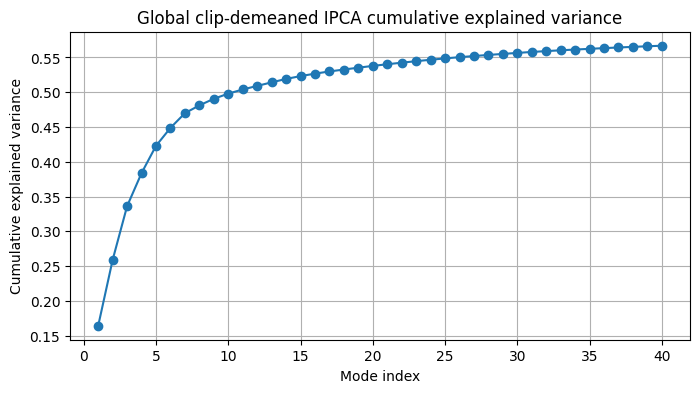

Mode 1: explained variance ratio = 0.1642
Mode 2: explained variance ratio = 0.0948
Mode 3: explained variance ratio = 0.0772
Mode 4: explained variance ratio = 0.0476
Mode 5: explained variance ratio = 0.0392
Mode 6: explained variance ratio = 0.0258
Mode 7: explained variance ratio = 0.0211
Mode 8: explained variance ratio = 0.0112
Mode 9: explained variance ratio = 0.0095
Mode 10: explained variance ratio = 0.0074
Mode 11: explained variance ratio = 0.0060
Mode 12: explained variance ratio = 0.0052
Mode 13: explained variance ratio = 0.0051
Mode 14: explained variance ratio = 0.0049
Mode 15: explained variance ratio = 0.0041


In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(evr) + 1), cum_evr, marker="o")
plt.xlabel("Mode index")
plt.ylabel("Cumulative explained variance")
plt.title("Global clip-demeaned IPCA cumulative explained variance")
plt.grid(True)
plt.show()

for k in range(min(len(evr), 15)):
    print(f"Mode {k+1}: explained variance ratio = {evr[k]:.4f}")

In [1]:
# ============================================================
# Block 10: Display the first few spatial modes
# ============================================================
num_modes_to_show = 40

fig, axes = plt.subplots(num_modes_to_show, 1, figsize=(6, 4 * num_modes_to_show))

if num_modes_to_show == 1:
    axes = [axes]

for k in range(num_modes_to_show):
    mode_img = components[k].reshape(H, W)
    mode_crop, _ = crop_by_fraction(mode_img, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

    im = axes[k].imshow(mode_crop, cmap="bwr")
    axes[k].set_title(f"Spatial mode {k+1} | EVR={evr[k]:.3f}")
    axes[k].axis("off")
    plt.colorbar(im, ax=axes[k], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
# ============================================================
# Block 11: Choose retained modes and project all frames
# ============================================================
# You can change this threshold after visual inspection
CUMULATIVE_THRESHOLD = 0.9

n_keep = np.searchsorted(cum_evr, CUMULATIVE_THRESHOLD) + 1
n_keep = min(n_keep, components.shape[0])

print("Keeping first", n_keep, "modes")

proj_cols = [f"mode_{i+1}" for i in range(n_keep)]
projection_records = []

for i, row in manifest_df.iterrows():
    try:
        frames = load_video_frames(
            row["abs_path"],
            grayscale=GRAYSCALE,
            resize_to=RESIZE_TO,
            frame_stride=FRAME_STRIDE,
            max_frames=MAX_FRAMES_PER_CLIP
        )

        T, H, W = frames.shape
        X = frames.reshape(T, H * W).astype(np.float32)
        Xc = X - np.mean(X, axis=0, keepdims=True)

        coeffs = ipca.transform(Xc)[:, :n_keep]   # (T, n_keep)

        for t in range(T):
            rec = {
                "rel_path": row["rel_path"],
                "rel_dir": row["rel_dir"],
                "file_name": row["file_name"],
                "subject": row["subject"],
                "word": row["word"],
                "frame_idx": t,
                "n_frames_in_clip": T,
            }

            # preserve path dependencies
            level_cols = [c for c in manifest_df.columns if c.startswith("path_level_")]
            for c_name in level_cols:
                rec[c_name] = row.get(c_name, "")

            for j in range(n_keep):
                rec[f"mode_{j+1}"] = coeffs[t, j]

            projection_records.append(rec)

        if (i + 1) % 20 == 0:
            print(f"Projected {i+1}/{len(manifest_df)} clips")

        del frames, X, Xc, coeffs
        gc.collect()

    except Exception as e:
        print("FAILED during projection:", row["rel_path"], "|", e)

proj_df = pd.DataFrame(projection_records)
print("Projection table shape:", proj_df.shape)

proj_csv = os.path.join(OUTPUT_DIR, "framewise_mode_coefficients.csv.gz")
proj_df.to_csv(proj_csv, index=False, compression="gzip")
print("Saved:", proj_csv)

Keeping first 40 modes
Projected 20/401 clips
Projected 40/401 clips
Projected 60/401 clips
Projected 80/401 clips
Projected 100/401 clips
Projected 120/401 clips
Projected 140/401 clips
Projected 160/401 clips
Projected 180/401 clips
Projected 200/401 clips
Projected 220/401 clips
Projected 240/401 clips
Projected 260/401 clips
Projected 280/401 clips
Projected 300/401 clips
Projected 320/401 clips
Projected 340/401 clips
Projected 360/401 clips
Projected 380/401 clips
Projected 400/401 clips
FAILED during projection: file_manifest_preview.csv | Could not open video: /content/drive/My Drive/Centre_align_cropped/file_manifest_preview.csv
Projection table shape: (50211, 48)


NameError: name 'OUTPUT_DIR' is not defined

In [ ]:
OUTPUT_DIR = '/content/drive/My Drive/Centre_align_cropped_output'
proj_csv = os.path.join(OUTPUT_DIR, "framewise_mode_coefficients.csv.gz")
proj_df.to_csv(proj_csv, index=False, compression="gzip")
print("Saved:", proj_csv)

Saved: /content/drive/My Drive/Centre_align_cropped_output/framewise_mode_coefficients.csv.gz


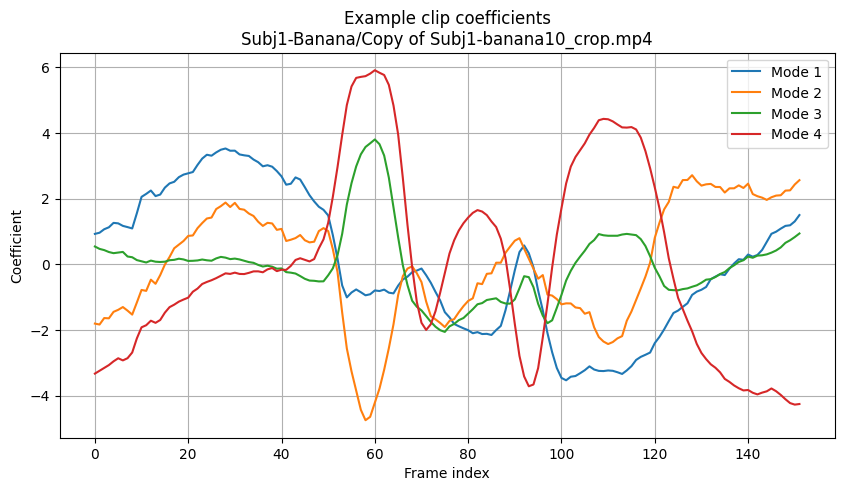

In [ ]:
# ============================================================
# Block 12: Quick visual inspection of projected coefficients
# ============================================================
example_rel_path = proj_df["rel_path"].iloc[0]
example_clip = proj_df[proj_df["rel_path"] == example_rel_path].copy()

modes_to_plot = min(4, n_keep)

plt.figure(figsize=(10, 5))
for j in range(modes_to_plot):
    plt.plot(example_clip["frame_idx"], example_clip[f"mode_{j+1}"], label=f"Mode {j+1}")

plt.xlabel("Frame index")
plt.ylabel("Coefficient")
plt.title(f"Example clip coefficients\n{example_rel_path}")
plt.legend()
plt.grid(True)
plt.show()

['Subj1-tomorrow/Copy of Subj1-tomorrow10_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow11_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow12_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow13_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow14_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow15_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow16_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow17_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow18_crop.mp4', 'Subj1-tomorrow/Copy of Subj1-tomorrow19_crop.mp4']


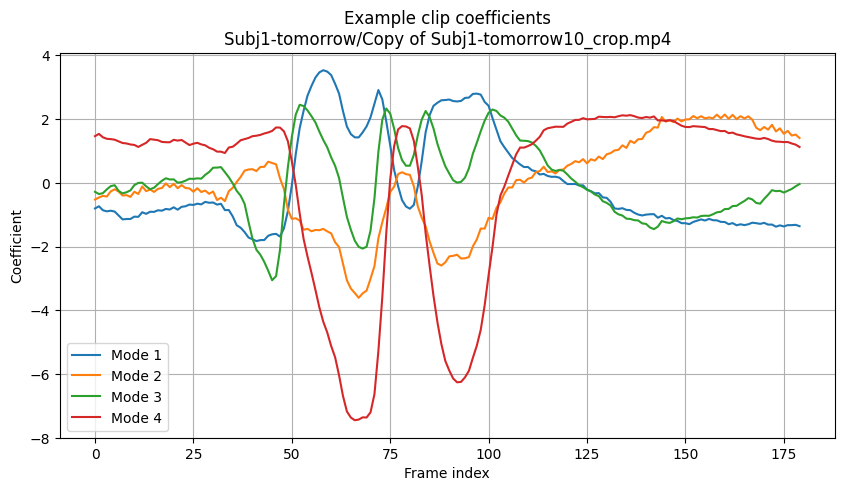

In [ ]:
subject_target = "Subj1"
word_target = "tomorrow"   # change this

candidate_paths = (
    proj_df.loc[
        (proj_df["subject"] == subject_target) &
        (proj_df["word"] == word_target),
        "rel_path"
    ]
    .drop_duplicates()
    .tolist()
)

print(candidate_paths[:10])   # inspect available clips

example_rel_path = candidate_paths[0]   # pick one clip
example_clip = proj_df[proj_df["rel_path"] == example_rel_path].copy()

modes_to_plot = min(4, n_keep)

plt.figure(figsize=(10, 5))
for j in range(modes_to_plot):
    plt.plot(example_clip["frame_idx"], example_clip[f"mode_{j+1}"], label=f"Mode {j+1}")

plt.xlabel("Frame index")
plt.ylabel("Coefficient")
plt.title(f"Example clip coefficients\n{example_rel_path}")
plt.legend()
plt.grid(True)
plt.show()

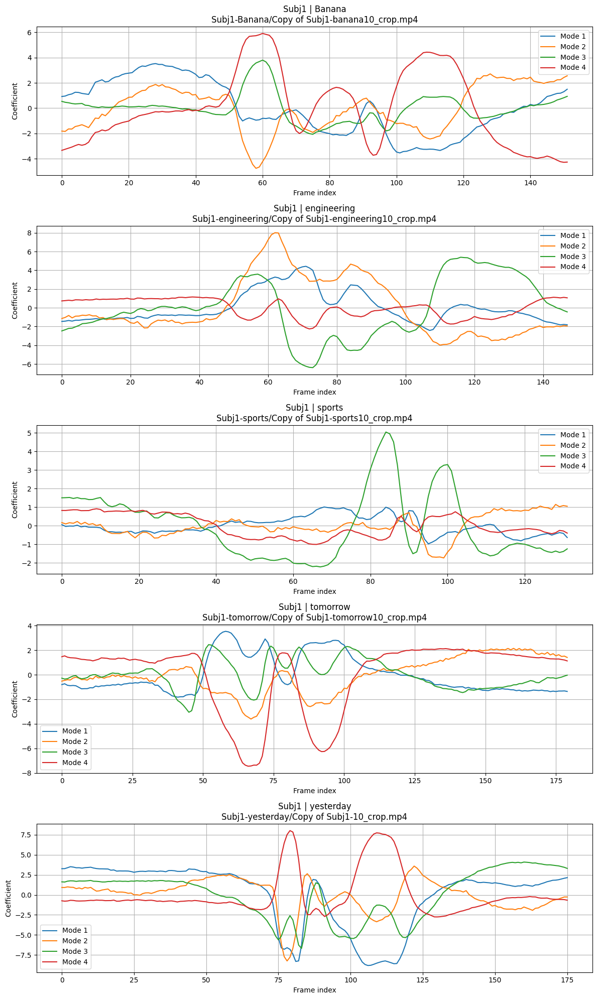

In [ ]:
subject_target = "Subj1"
modes_to_plot = min(4, n_keep)

available_words = sorted(
    proj_df.loc[proj_df["subject"] == subject_target, "word"].dropna().unique()
)

n_words = len(available_words)
fig, axes = plt.subplots(n_words, 1, figsize=(12, 4 * n_words), sharex=False)

if n_words == 1:
    axes = [axes]

for ax, word_target in zip(axes, available_words):
    candidate_paths = (
        proj_df.loc[
            (proj_df["subject"] == subject_target) &
            (proj_df["word"] == word_target),
            "rel_path"
        ]
        .drop_duplicates()
        .tolist()
    )

    if len(candidate_paths) == 0:
        ax.set_title(f"{subject_target} | {word_target} | no clip found")
        ax.axis("off")
        continue

    example_rel_path = candidate_paths[0]
    example_clip = proj_df[proj_df["rel_path"] == example_rel_path].copy()

    for j in range(modes_to_plot):
        ax.plot(
            example_clip["frame_idx"],
            example_clip[f"mode_{j+1}"],
            label=f"Mode {j+1}"
        )

    ax.set_title(f"{subject_target} | {word_target}\n{example_rel_path}")
    ax.set_xlabel("Frame index")
    ax.set_ylabel("Coefficient")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

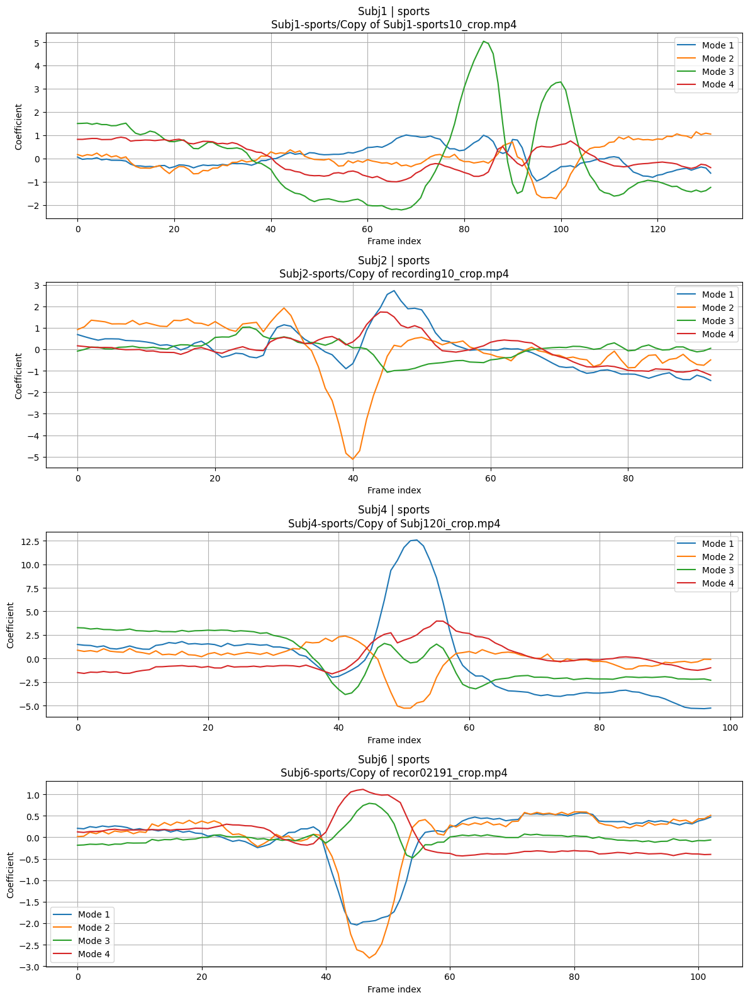

In [ ]:
word_target = "sports"   # change this
modes_to_plot = min(4, n_keep)

available_subjects = sorted(
    proj_df.loc[proj_df["word"] == word_target, "subject"].dropna().unique()
)

n_subj = len(available_subjects)
fig, axes = plt.subplots(n_subj, 1, figsize=(12, 4 * n_subj), sharex=False)

if n_subj == 1:
    axes = [axes]

for ax, subject_target in zip(axes, available_subjects):
    candidate_paths = (
        proj_df.loc[
            (proj_df["subject"] == subject_target) &
            (proj_df["word"] == word_target),
            "rel_path"
        ]
        .drop_duplicates()
        .tolist()
    )

    if len(candidate_paths) == 0:
        ax.set_title(f"{subject_target} | {word_target} | no clip found")
        ax.axis("off")
        continue

    example_rel_path = candidate_paths[0]
    example_clip = proj_df[proj_df["rel_path"] == example_rel_path].copy()

    for j in range(modes_to_plot):
        ax.plot(
            example_clip["frame_idx"],
            example_clip[f"mode_{j+1}"],
            label=f"Mode {j+1}"
        )

    ax.set_title(f"{subject_target} | {word_target}\n{example_rel_path}")
    ax.set_xlabel("Frame index")
    ax.set_ylabel("Coefficient")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Block 13: Build clip-level feature table from frame coefficients
# ============================================================
group_cols = ["rel_path", "rel_dir", "file_name", "subject", "word", "n_frames_in_clip"]
mode_cols = [f"mode_{j+1}" for j in range(n_keep)]

agg_dict = {}
for c in mode_cols:
    agg_dict[c] = ["mean", "std", "max", "min"]

clip_feat_df = proj_df.groupby(group_cols).agg(agg_dict)
clip_feat_df.columns = ["_".join(col).strip() for col in clip_feat_df.columns.to_flat_index()]
clip_feat_df = clip_feat_df.reset_index()

clip_feat_csv = os.path.join(OUTPUT_DIR, "clip_level_features.csv")
clip_feat_df.to_csv(clip_feat_csv, index=False)
print("Saved:", clip_feat_csv)

display(clip_feat_df.head())

Saved: /content/drive/My Drive/Centre_align_cropped_output/clip_level_features.csv


,rel_path,rel_dir,file_name,subject,word,n_frames_in_clip,mode_1_mean,mode_1_std,mode_1_max,mode_1_min,...,mode_38_max,mode_38_min,mode_39_mean,mode_39_std,mode_39_max,mode_39_min,mode_40_mean,mode_40_std,mode_40_max,mode_40_min
0,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1-Banana,Copy of Subj1-banana10_crop.mp4,Subj1,Banana,152,0.000016,2.091251,3.522582,-3.535089,...,0.402812,-0.223847,0.000002,0.235513,0.564801,-0.377097,1.003455e-06,0.271347,0.547872,-0.461410
1,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1-Banana,Copy of Subj1-banana11_crop.mp4,Subj1,Banana,166,-0.000031,2.454241,3.673373,-4.210080,...,0.271798,-0.315236,-0.000002,0.221587,0.515035,-0.317567,2.493982e-07,0.277521,0.418947,-0.503694
2,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1-Banana,Copy of Subj1-banana12_crop.mp4,Subj1,Banana,163,-0.000036,5.904729,7.407674,-8.420578,...,0.288924,-0.267174,-0.000003,0.519021,0.845955,-0.835539,2.677859e-06,0.197122,0.513994,-0.297198
3,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1-Banana,Copy of Subj1-banana13_crop.mp4,Subj1,Banana,202,-0.000031,4.727525,6.129084,-8.582205,...,0.604692,-0.269582,-0.000003,0.326622,0.532729,-0.526162,4.331640e-06,0.234519,0.446852,-0.480174
4,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1-Banana,Copy of Subj1-banana14_crop.mp4,Subj1,Banana,207,-0.000012,3.121989,4.661723,-6.876610,...,0.451178,-0.341622,-0.000002,0.114521,0.244957,-0.280137,4.044306e-06,0.169832,0.301187,-0.513208


In [ ]:
# ============================================================
# Block 14: Optional correlation-ready summary
# ============================================================
# Simple example: use mean coefficients only
mean_feature_cols = [c for c in clip_feat_df.columns if c.endswith("_mean")]

corr_ready_df = clip_feat_df[["rel_path", "subject", "word"] + mean_feature_cols].copy()

corr_csv = os.path.join(OUTPUT_DIR, "correlation_ready_clip_features.csv")
corr_ready_df.to_csv(corr_csv, index=False)
print("Saved:", corr_csv)

display(corr_ready_df.head())

Saved: /content/drive/My Drive/Centre_align_cropped_output/correlation_ready_clip_features.csv


,rel_path,subject,word,mode_1_mean,mode_2_mean,mode_3_mean,mode_4_mean,mode_5_mean,mode_6_mean,mode_7_mean,...,mode_31_mean,mode_32_mean,mode_33_mean,mode_34_mean,mode_35_mean,mode_36_mean,mode_37_mean,mode_38_mean,mode_39_mean,mode_40_mean
0,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1,Banana,0.000016,-0.000046,5.612241e-07,-8.387664e-07,0.000020,0.000008,0.000004,...,0.000003,-9.311444e-07,-1.526533e-06,4.326541e-06,-0.000003,-2.188936e-07,4.127297e-06,2.332019e-06,0.000002,1.003455e-06
1,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1,Banana,-0.000031,-0.000036,-2.680219e-05,-1.247098e-05,0.000025,0.000015,-0.000015,...,-0.000004,3.837185e-06,-4.572390e-06,1.626040e-06,0.000002,-3.645642e-06,1.386465e-06,4.807703e-07,-0.000002,2.493982e-07
2,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1,Banana,-0.000036,-0.000009,-5.470183e-06,1.644801e-05,0.000037,0.000025,-0.000026,...,-0.000005,6.151620e-06,-2.168440e-06,5.896757e-07,0.000007,-2.672862e-07,-9.582119e-07,-1.756453e-06,-0.000003,2.677859e-06
3,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1,Banana,-0.000031,0.000003,-5.106110e-06,-1.478748e-06,0.000052,0.000019,-0.000029,...,-0.000002,7.793357e-06,-1.685784e-06,-4.225371e-07,0.000011,1.045600e-06,-3.407204e-06,-3.411901e-06,-0.000003,4.331640e-06
4,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1,Banana,-0.000012,0.000021,2.196961e-06,-3.214320e-06,0.000063,0.000019,-0.000021,...,-0.000002,8.963192e-06,-3.257541e-07,-1.008227e-06,0.000012,3.356851e-06,-5.583749e-06,-3.710023e-06,-0.000002,4.044306e-06


In [ ]:
# ============================================================
# Block 15: t-SNE on clip-level features
# ============================================================
feature_cols = [c for c in clip_feat_df.columns if c not in ["rel_path", "rel_dir", "file_name", "subject", "word", "n_frames_in_clip"]]

X_feat = clip_feat_df[feature_cols].values.astype(np.float32)
X_feat = StandardScaler().fit_transform(X_feat)

tsne = TSNE(
    n_components=2,
    perplexity=min(TSNE_PERPLEXITY, max(5, len(clip_feat_df)//3)),
    random_state=TSNE_RANDOM_STATE,
    init="pca",
    learning_rate="auto"
)
X_tsne = tsne.fit_transform(X_feat)

tsne_df = clip_feat_df[["rel_path", "subject", "word"]].copy()
tsne_df["tsne_1"] = X_tsne[:, 0]
tsne_df["tsne_2"] = X_tsne[:, 1]

tsne_csv = os.path.join(OUTPUT_DIR, "tsne_clip_embedding.csv")
tsne_df.to_csv(tsne_csv, index=False)
print("Saved:", tsne_csv)

Saved: /content/drive/My Drive/Centre_align_cropped_output/tsne_clip_embedding.csv


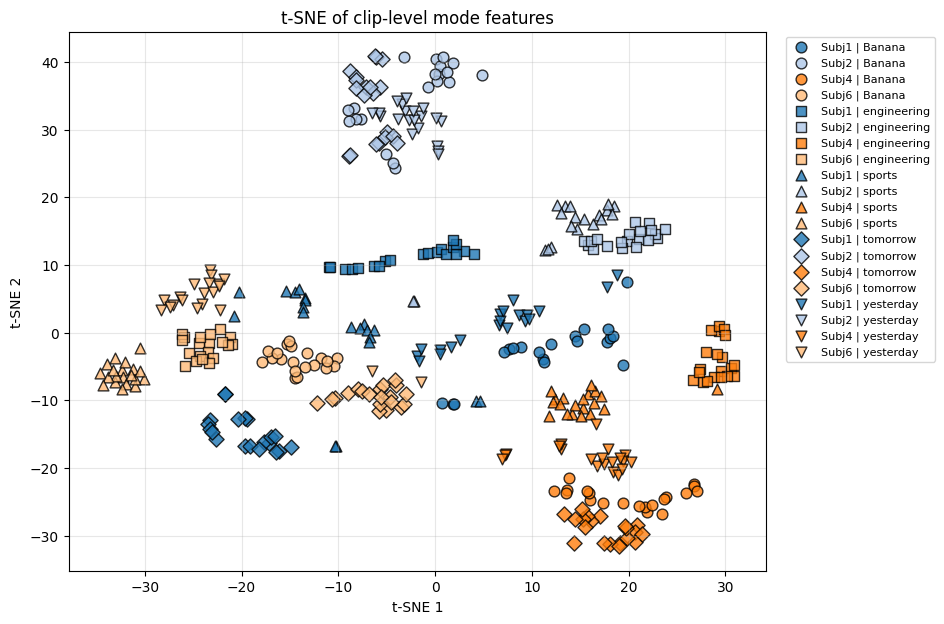

In [ ]:
# ============================================================
# Block 16: Plot t-SNE
# ============================================================
subjects = sorted(tsne_df["subject"].astype(str).unique())
words = sorted(tsne_df["word"].astype(str).unique())

subject_to_color = {s: plt.cm.tab20(i % 20) for i, s in enumerate(subjects)}
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">"]
word_to_marker = {w: markers[i % len(markers)] for i, w in enumerate(words)}

plt.figure(figsize=(9, 7))
for w in words:
    sub = tsne_df[tsne_df["word"].astype(str) == str(w)]
    for s in subjects:
        ss = sub[sub["subject"].astype(str) == str(s)]
        if len(ss) == 0:
            continue
        plt.scatter(
            ss["tsne_1"], ss["tsne_2"],
            c=[subject_to_color[s]],
            marker=word_to_marker[w],
            label=f"{s} | {w}",
            alpha=0.8,
            edgecolors="k",
            s=60
        )

plt.title("t-SNE of clip-level mode features")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True, alpha=0.3)

# comment out if legend is too large
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.show()

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /content/drive/My Drive/Centre_align_cropped_output/umap_clip_embedding.csv


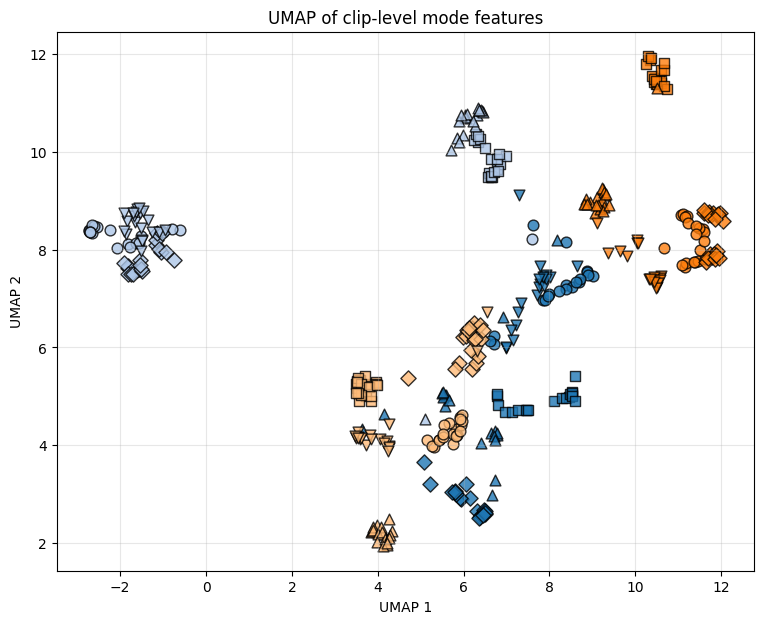

In [ ]:
# ============================================================
# Block 17: Optional UMAP
# ============================================================
if HAS_UMAP:
    reducer = umap.UMAP(
        n_components=2,
        random_state=UMAP_RANDOM_STATE,
        n_neighbors=min(15, max(5, len(clip_feat_df)//4)),
        min_dist=0.1
    )
    X_umap = reducer.fit_transform(X_feat)

    umap_df = clip_feat_df[["rel_path", "subject", "word"]].copy()
    umap_df["umap_1"] = X_umap[:, 0]
    umap_df["umap_2"] = X_umap[:, 1]

    umap_csv = os.path.join(OUTPUT_DIR, "umap_clip_embedding.csv")
    umap_df.to_csv(umap_csv, index=False)
    print("Saved:", umap_csv)

    plt.figure(figsize=(9, 7))
    for w in words:
        sub = umap_df[umap_df["word"].astype(str) == str(w)]
        for s in subjects:
            ss = sub[sub["subject"].astype(str) == str(s)]
            if len(ss) == 0:
                continue
            plt.scatter(
                ss["umap_1"], ss["umap_2"],
                c=[subject_to_color[s]],
                marker=word_to_marker[w],
                alpha=0.8,
                edgecolors="k",
                s=60
            )

    plt.title("UMAP of clip-level mode features")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("UMAP not installed. Skip or install with: !pip install umap-learn")

In [ ]:
# ============================================================
# Block A: Build per-clip trajectory features from mode 2 and 3
# Assumes proj_df already exists with:
# rel_path, subject, word, frame_idx, mode_1, mode_2, ...
# ============================================================

import numpy as np
import pandas as pd

# ---------------- USER SETTINGS ----------------
MODES_TO_USE = [2, 3, 4]         # 1-based mode numbers
RESAMPLED_LEN = 150            # common normalized trajectory length
NORMALIZE_PER_CLIP = True     # recommended first pass
NORMALIZE_METHOD = "zscore"   # "zscore" or "minmax"

required_cols = ["rel_path", "subject", "word", "frame_idx"] + [f"mode_{m}" for m in MODES_TO_USE]
missing = [c for c in required_cols if c not in proj_df.columns]
if len(missing) > 0:
    raise ValueError(f"proj_df missing required columns: {missing}")

def resample_1d(y, target_len):
    y = np.asarray(y, dtype=np.float32)
    n = len(y)
    if n == 0:
        return np.full(target_len, np.nan, dtype=np.float32)
    if n == 1:
        return np.full(target_len, y[0], dtype=np.float32)

    x_old = np.linspace(0.0, 1.0, n)
    x_new = np.linspace(0.0, 1.0, target_len)
    y_new = np.interp(x_new, x_old, y)
    return y_new.astype(np.float32)

def normalize_trace(y, method="zscore"):
    y = np.asarray(y, dtype=np.float32)
    if method == "zscore":
        mu = np.mean(y)
        sd = np.std(y)
        if sd < 1e-8:
            return y - mu
        return (y - mu) / sd
    elif method == "minmax":
        ymin = np.min(y)
        ymax = np.max(y)
        if ymax - ymin < 1e-8:
            return y - ymin
        return (y - ymin) / (ymax - ymin)
    else:
        return y

traj_records = []
feature_rows = []

grouped = proj_df.groupby(["rel_path", "subject", "word"], dropna=False)

for (rel_path, subject, word), g in grouped:
    g = g.sort_values("frame_idx").copy()

    feat_parts = []
    rec = {
        "rel_path": rel_path,
        "subject": subject,
        "word": word,
        "n_frames": len(g),
    }

    for m in MODES_TO_USE:
        y = g[f"mode_{m}"].values.astype(np.float32)
        y_rs = resample_1d(y, RESAMPLED_LEN)

        if NORMALIZE_PER_CLIP:
            y_rs = normalize_trace(y_rs, NORMALIZE_METHOD)

        rec[f"mode_{m}_traj"] = y_rs
        feat_parts.append(y_rs)

    feature_vec = np.concatenate(feat_parts, axis=0)

    traj_records.append(rec)
    feature_rows.append(feature_vec)

traj_meta_df = pd.DataFrame(traj_records)
X_traj = np.stack(feature_rows, axis=0).astype(np.float32)

print("Trajectory feature matrix shape:", X_traj.shape)
print("Metadata shape:", traj_meta_df.shape)
display(traj_meta_df[["rel_path", "subject", "word", "n_frames"]].head())

Trajectory feature matrix shape: (400, 450)
Metadata shape: (400, 7)


,rel_path,subject,word,n_frames
0,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1,Banana,152
1,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1,Banana,166
2,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1,Banana,163
3,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1,Banana,202
4,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1,Banana,207


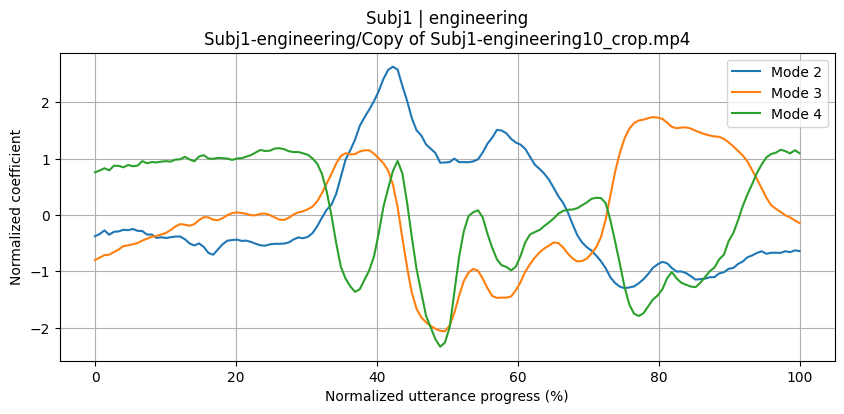

In [ ]:
# ============================================================
# Block B: Inspect a few normalized resampled trajectories
# ============================================================

example_idx = 20   # change if needed
row = traj_meta_df.iloc[example_idx]

plt.figure(figsize=(10, 4))
for m in MODES_TO_USE:
    y = row[f"mode_{m}_traj"]
    plt.plot(np.linspace(0, 100, len(y)), y, label=f"Mode {m}")

plt.xlabel("Normalized utterance progress (%)")
plt.ylabel("Normalized coefficient")
plt.title(f"{row['subject']} | {row['word']}\n{row['rel_path']}")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# ============================================================
# Block C: t-SNE on mode 2/3 trajectory features
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

# global standardization across clips
X_traj_scaled = StandardScaler().fit_transform(X_traj)

perplexity_use = min(10, max(5, len(traj_meta_df) // 3))
print(perplexity_use)
tsne = TSNE(
    n_components=2,
    perplexity=perplexity_use,
    random_state=41,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(X_traj_scaled)

traj_tsne_df = traj_meta_df[["rel_path", "subject", "word", "n_frames"]].copy()
traj_tsne_df["tsne_1"] = X_tsne[:, 0]
traj_tsne_df["tsne_2"] = X_tsne[:, 1]

display(traj_tsne_df.head())
print("t-SNE finished.")

10


,rel_path,subject,word,n_frames,tsne_1,tsne_2
0,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1,Banana,152,7.014663,16.736008
1,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1,Banana,166,6.165533,15.444664
2,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1,Banana,163,-40.345810,27.215759
3,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1,Banana,202,7.959039,18.646763
4,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1,Banana,207,-1.087100,-20.471361


t-SNE finished.


In [ ]:
# ============================================================
# Block D: UMAP on mode 2/3 trajectory features
# ============================================================

try:
    import umap.umap_ as umap
except Exception as e:
    raise ImportError("UMAP not installed. Run: !pip install umap-learn") from e

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=min(15, max(5, len(traj_meta_df) // 4)),
    min_dist=0.15,
    random_state=41
)

X_umap = reducer.fit_transform(X_traj_scaled)

traj_umap_df = traj_meta_df[["rel_path", "subject", "word", "n_frames"]].copy()
traj_umap_df["umap_1"] = X_umap[:, 0]
traj_umap_df["umap_2"] = X_umap[:, 1]

display(traj_umap_df.head())
print("UMAP finished.")

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,rel_path,subject,word,n_frames,umap_1,umap_2
0,Subj1-Banana/Copy of Subj1-banana10_crop.mp4,Subj1,Banana,152,-1.687345,-0.704032
1,Subj1-Banana/Copy of Subj1-banana11_crop.mp4,Subj1,Banana,166,-1.583544,-0.878055
2,Subj1-Banana/Copy of Subj1-banana12_crop.mp4,Subj1,Banana,163,-2.928515,-0.625280
3,Subj1-Banana/Copy of Subj1-banana13_crop.mp4,Subj1,Banana,202,-1.810430,-0.616392
4,Subj1-Banana/Copy of Subj1-banana14_crop.mp4,Subj1,Banana,207,1.844895,-1.364422


UMAP finished.


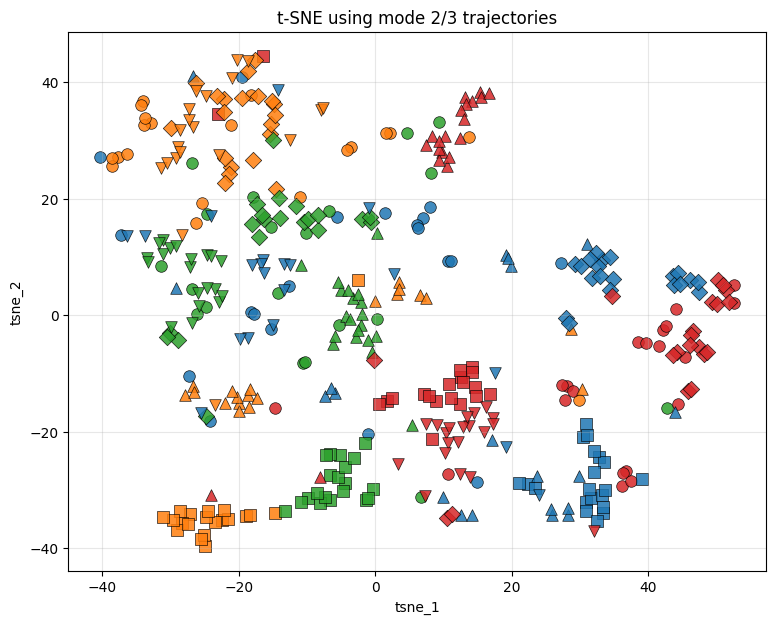

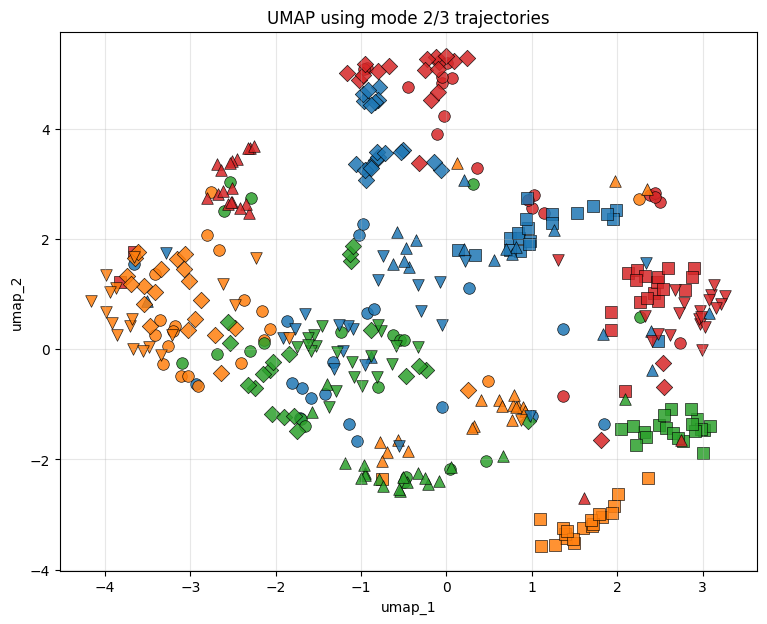

In [ ]:
# ============================================================
# Block E: Plot embeddings with subject colors and word markers
# ============================================================

subjects = sorted(traj_meta_df["subject"].dropna().astype(str).unique())
words = sorted(traj_meta_df["word"].dropna().astype(str).unique())

subject_to_color = {s: plt.cm.tab10(i % 10) for i, s in enumerate(subjects)}
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">"]
word_to_marker = {w: markers[i % len(markers)] for i, w in enumerate(words)}

def plot_embedding(df, xcol, ycol, title):
    plt.figure(figsize=(9, 7))

    for w in words:
        sub_w = df[df["word"].astype(str) == str(w)]
        for s in subjects:
            ss = sub_w[sub_w["subject"].astype(str) == str(s)]
            if len(ss) == 0:
                continue

            plt.scatter(
                ss[xcol],
                ss[ycol],
                c=[subject_to_color[s]],
                marker=word_to_marker[w],
                s=70,
                alpha=0.85,
                edgecolors="k",
                linewidths=0.5
            )

    plt.title(title)
    plt.xlabel(xcol)
    plt.ylabel(ycol)
    plt.grid(True, alpha=0.3)
    plt.show()

plot_embedding(traj_tsne_df, "tsne_1", "tsne_2", "t-SNE using mode 2/3 trajectories")
plot_embedding(traj_umap_df, "umap_1", "umap_2", "UMAP using mode 2/3 trajectories")

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

# ============================================================
# 1. Mount Drive
# ============================================================
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')
else:
    print("Drive already mounted.")

# ============================================================
# 2. Config & Path Check
# ============================================================
OUTPUT_DIR = '/content/drive/My Drive/Centre_align_cropped_output'
H, W = 192, 256
XMIN_FRAC, XMAX_FRAC = 0.18, 0.82
YMIN_FRAC, YMAX_FRAC = 0.08, 0.92

def crop_by_fraction(img, xmin_frac, xmax_frac, ymin_frac, ymax_frac):
    H_img, W_img = img.shape
    x0, x1 = int(np.floor(W_img * xmin_frac)), int(np.ceil(W_img * xmax_frac))
    y0, y1 = int(np.floor(H_img * ymin_frac)), int(np.ceil(H_img * ymax_frac))
    return img[y0:y1, x0:x1], (x0, x1, y0, y1)

# ============================================================
# 3. Block 1: 8x5 plot of spatial modes (Diverging Blue-Red Map)
# =================================="
# Blue = Negative, Red = Positive
# ============================================================
basis_npz_path = os.path.join(OUTPUT_DIR, "global_ipca_basis.npz")

if os.path.exists(basis_npz_path):
    print("--- Generating Block 1: 8x5 plot of spatial modes ---")
    basis_data = np.load(basis_npz_path)
    components = basis_data["components"]
    evr = basis_data["explained_variance_ratio"]
    n_comp = basis_data["n_components"][0]

    rows, cols = 8, 5
    fig, axes = plt.subplots(rows, cols, figsize=(15, 20))
    axes = axes.flatten()
    for k in range(min(40, n_comp)):
        mode_img = components[k].reshape(H, W)
        mode_crop, _ = crop_by_fraction(mode_img, XMIN_FRAC, XMAX_FRAC, YMIN_FRAC, YMAX_FRAC)

        # Use bwr (blue-white-red) to clearly separate negative (blue) from positive (red)
        # We set a symmetric vmin/vmax so that 0 is exactly white
        v_limit = np.abs(mode_crop).max()
        axes[k].imshow(mode_crop, cmap="coolwarm", vmin=-v_limit, vmax=v_limit)
        axes[k].set_title(f"M{k+1} EVR={evr[k]:.3f}", fontsize=8)
        axes[k].axis("off")

    for i in range(min(40, n_comp), len(axes)): fig.delaxes(axes[i])
    plt.suptitle("First 40 Spatial Modes (Blue=Negative, Red=Positive)", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print(f"Missing file: {basis_npz_path}")

Output hidden; open in https://colab.research.google.com to view.


--- Generating Block 2: 2x2 plot of coefficient traces ---


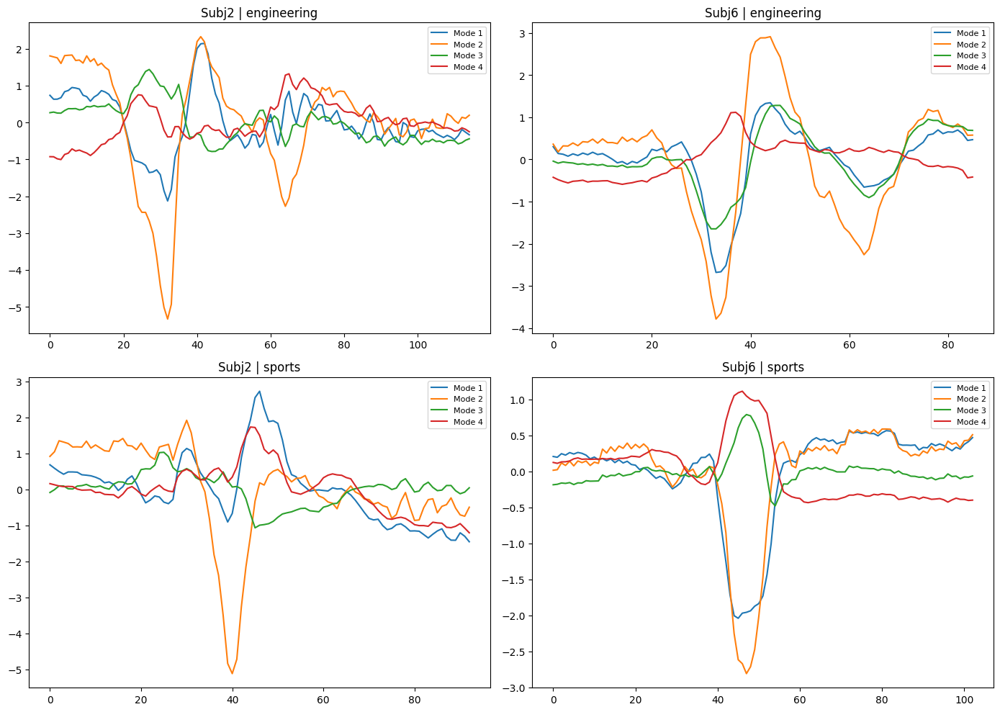

In [13]:
# ============================================================
# 4. Block 2: 2x2 plot of coefficient traces (Orange & Blue)
# ============================================================
proj_csv_path = os.path.join(OUTPUT_DIR, "framewise_mode_coefficients.csv.gz")

if os.path.exists(proj_csv_path):
    print("\n--- Generating Block 2: 2x2 plot of coefficient traces ---")
    proj_df = pd.read_csv(proj_csv_path)
    target_subjects = ["Subj2", "Subj6"]
    target_words = ["engineering", "sports"]
    modes_to_plot = [1, 2, 3, 4]

    # Explicit Orange and Blue colors for the 4 modes
    mode_colors = {
        1: "#FF8C00", # Dark Orange
        2: "#1E90FF", # Dodger Blue
        3: "#FF4500", # Orange Red
        4: "#000080"  # Navy Blue
    }

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    for r_idx, word in enumerate(target_words):
        for c_idx, subject in enumerate(target_subjects):
            ax = axes[r_idx, c_idx]
            clip_data = proj_df[(proj_df["subject"] == subject) & (proj_df["word"] == word)]
            paths = clip_data["rel_path"].unique()
            if len(paths) > 0:
                example_clip = clip_data[clip_data["rel_path"] == paths[0]].sort_values("frame_idx")
                for m in modes_to_plot:
                    if f"mode_{m}" in example_clip.columns:
                        ax.plot(
                            example_clip["frame_idx"],
                            example_clip[f"mode_{m}"],
                            label=f"Mode {m}",
                            color=mode_colors.get(m, None),
                            linewidth=2
                        )
                ax.set_title(f"{subject} | {word}", fontweight='bold')
                ax.legend(fontsize=8)
                ax.grid(True, alpha=0.3)
            else:
                ax.set_title(f"{subject} | {word} (Not Found)")

    plt.suptitle("Coefficient Traces (Orange & Blue Theme)", fontsize=16, y=0.98)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
else:
    print(f"Missing file: {proj_csv_path}")